# Structure-Aware Continuous Convolution for Attention Augmentation and Verified Weight Repair

*Research study RQ1-M / RQ6-M · executable Google Colab manuscript · 15 November 2026 · preliminary exploratory evidence*

## Abstract

Attention-based models learn content-dependent interactions but do not explicitly encode a time-varying causal convolution over past observations. Coupled Continuous Convolutional Neural Networks (CCNNs) have previously introduced a representation in which an accumulated lag-dependent convolution is expressed through a partial differential equation (PDE) and subsequently drives an ordinary differential equation (ODE) [1]. This study examines two independent hypotheses: (i) whether a compact lag-structured convolution provides a useful complement to self-attention and (ii) whether the same parameterization permits precise, bounded adaptation following a controlled change in the relevant historical delay. To test the first hypothesis, we construct an analytically specified noisy sequence generator with time-dependent delayed-chirp filters and compare attention alone against static convolution, query-conditioned unstructured convolution, a small exponential state-space model, and attention augmented with the proposed structured lag kernel. To test the second, we train models on the original process, introduce a known delay shift in a held-out operating domain, and compare one-parameter Jacobian, Adam, and random-search repairs under validation-based acceptance. Evaluation uses independent synthetic sequences and reports test errors, parameter counts, compute time, error under changing query dynamics, negative controls, and the failure rate of repair. **Expected outcomes are treated as hypotheses; the two-seed local run presented later is exploratory and is not evidence of general superiority or language-model weight reasoning.** A separate optional audit tests three public Hugging Face instruction models as numeric weight proposers without supplying them reference weights.

## 1. Invariant research question

> **Can the mathematical structure of coupled continuous convolution make attention more effective and neural-network weight repairs more precise than less structured alternatives?**

The two contributions are evaluated *separately*. A positive result for forecasting does not establish repair superiority; successful numerical repair does not establish genuine LLM reasoning. The [research charter](https://github.com/mansura-habiba/ode_nn/blob/master/notebooks/RESEARCH_QUESTIONS_CCNN_ATTENTION_WEIGHT_REPAIR.md) is the source of record.

### Falsifiable hypotheses

**H-A (augmentation):** adding a compact, time-varying causal lag kernel to attention improves held-out prediction over attention alone, static convolution, an exponential memory model, and a general query-conditioned discrete convolution under similar model capacity.

**H-B (structured repair):** following a known lag displacement, a single edit to the structured delay parameter achieves better held-out new-domain prediction than a single arbitrary filter-coordinate edit, without affecting the original domain.

**H-C (mechanism specificity):** a delay-only edit does not fully repair a frequency-change defect. A no-defect audit should not accept spurious edits.

**H-D (LLM proposer):** an open-weight instruction model can propose a valid, bounded, useful parameter edit; the advantage, if any, must exceed numerical/Adam/random baselines after accounting for inference cost. H-D is **not** assessed unless the optional Hugging Face cell runs successfully.

## 2. Source basis and proposed method

Habiba and Pearlmutter [1, equations (2)–(6)] define a time-varying causal kernel over history lag \(\tau\). Their PDE state satisfies

\[
\partial_{\tau}u(t,\tau)=K_{\theta}(\tau,t)y(t-\tau),\quad u(t,0)=0,\qquad \dot y(t)=f(u(t,T)).
\]

**Our toy is an adaptation, not a faithful reproduction of the original chirp experiment.** The observed driving signal \(x(t)\) is exogenous, and a kernel response \(m(t)=u(t,T)\) drives a leaky latent ODE \(\dot z=-\lambda z+\lambda\tanh(2m)\). A finite lag-grid quadrature computes the lag PDE (via cumulative sums), and the latent ODE is integrated by an exact exponential update under a piecewise-constant forcing approximation. This isolates the mathematical effect of *kernel structure* without numerical-solver variation.

The learned kernel has the form

\[
K_{\theta}(\tau,t)\propto
\exp\!\left[-\frac{(\tau-\mu_0-\mu_q q(t))^2}{2\sigma^2}\right]
\cos\!\left(2\pi[f_0\tau+c\tau^2]\right).
\]

Here the query \(q(t)\) determines a moving historical response; the parameter \(\mu_0\) has an explicit delay meaning. This is deliberately a low-dimensional **structured matched filter**. We compare it with a query-conditioned 14-weight filter, rather than a static filter alone, to test whether *compact structure* adds value beyond conditional convolution.

### Method architecture

The graph below highlights what is new and what is shared. The lag PDE is the **integration over past time**, not a diffusion PDE over spatial channels.


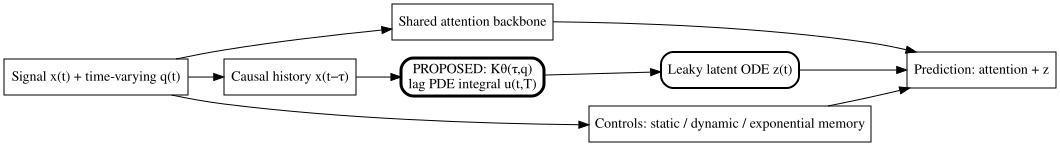

In [1]:
# Method diagram: visually identify the proposed mechanism, not an assumed winner.
try:
    from graphviz import Digraph
    from IPython.display import display
    g=Digraph('method',graph_attr={'rankdir':'LR'})
    g.node('in','Signal x(t) + time-varying q(t)',shape='box')
    g.node('att','Shared attention backbone',shape='box')
    g.node('hist','Causal history x(t−τ)',shape='box')
    g.node('lag','PROPOSED: Kθ(τ,q)\nlag PDE integral u(t,T)',shape='box',style='rounded,bold',penwidth='3')
    g.node('ode','Leaky latent ODE z(t)',shape='box',style='rounded,bold',penwidth='2')
    g.node('out','Prediction: attention + z',shape='box')
    g.node('controls','Controls: static / dynamic / exponential memory',shape='box')
    for a,b in [('in','att'),('in','hist'),('hist','lag'),('lag','ode'),('ode','out'),('att','out'),('in','controls'),('controls','out')]:g.edge(a,b)
    display(g)
except Exception as ex: print('Optional Graphviz rendering unavailable:',ex)


### Scientific rationale for the proposed architecture

The proposed model tests whether a parameterized causal memory operator contributes predictive information that cannot be learned as efficiently by the shared attention backbone or by less structured temporal filters. The experiment therefore evaluates **incremental forecasting performance** and **repairability** as separate outcomes. The schematic specifies the comparison; it is not itself experimental evidence.

## 3. Expected outcomes and empirical boundaries

If the source generator's filter is truly structured, its low-dimensional parameterization should offer improved sample efficiency and a small repair surface. A sufficiently expressive dynamic filter may also learn the generator. **A favorable matched-generator result is not evidence of broad architectural superiority.** The original-domain behavior is protected by an *explicit domain-gated repair parameter*; this preservation is by construction and should not be advertised as a learned general non-regression guarantee. A generic one-scalar dynamic-filter edit is a deliberately restricted control; broader low-rank or full-kernel editing may be much stronger.

### Implementation protocol

The next cell includes all model definitions. There is no external dataset, checkpoint, token, or GitHub file required. The learned and reference kernels share a function family by design. `QUICK=1` provides a smoke test; the default uses two seeds, 30 epochs, and 480 training sequences per seed. CPU suffices.


In [2]:
"""RQ1-M and RQ6-M reproducible toy: time-varying causal lag kernel and repair.
No external datasets, GPU, authentication, or downloads required.
"""
from __future__ import annotations
import os, json, time, copy, math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

N=48; L=14; W=32; SEEDS=[11,23]; torch.set_num_threads(2)

def make_data(count:int, seed:int, shift=0.0, regime='standard'):
    r=np.random.default_rng(seed)
    t=np.linspace(0,1,N,dtype=np.float32)[None,:]
    q0=r.uniform(-.7,.7,(count,1)).astype(np.float32)
    slope=r.uniform(-.25,.25,(count,1)).astype(np.float32) if regime=='standard' else r.uniform(-.85,.85,(count,1)).astype(np.float32)
    q=np.clip(q0+slope*(t-.5)+.23*np.sin(2*np.pi*(t+r.uniform(0,1,(count,1)))), -1.5,1.5).astype(np.float32)
    x=r.normal(0,.4,(count,N)).astype(np.float32)
    # randomized chirp-like motifs with unrelated distractors
    for b in range(count):
        for _ in range(3):
            loc=int(r.integers(0,N))
            idx=np.arange(N)-loc
            envelope=np.exp(-.5*(idx/float(r.uniform(3,7)))**2)
            phase=2*np.pi*(r.uniform(.12,.28)*idx + r.uniform(.001,.009)*idx**2)
            x[b]+=float(r.choice([-1,1])*r.uniform(.3,1.2))*envelope*np.cos(phase)
    return torch.tensor(x),torch.tensor(q)

def lag_history(x):
    # H[b,t,j]=x[b,t-j] and zero for t<j (causal prehistory)
    return torch.stack([F.pad(x[:,:N-j],(j,0)) for j in range(L)],dim=-1)

def kernel(q,mu0,muq,logsigma,freq,chirp,domain_shift=None):
    tau=torch.arange(L,device=q.device,dtype=q.dtype).view(1,1,L)/(L-1)
    mu=mu0+muq*q.unsqueeze(-1)
    if domain_shift is not None:mu=mu+domain_shift
    width=F.softplus(torch.as_tensor(logsigma,device=q.device,dtype=q.dtype))+.04
    envelope=torch.exp(-.5*((tau-mu)/width)**2)
    phase=2*torch.pi*(freq*tau+chirp*tau.square())
    raw=envelope*torch.cos(phase)
    return raw/(raw.square().sum(-1,keepdim=True).sqrt()+1e-7)

def integrate_drive(m):
    # z' = -8z + 8 tanh(2m); exponential time stepping over dt=1/N.
    alpha=1.-math.exp(-8./N)
    z=torch.zeros_like(m[:,0])
    for j in range(m.shape[1]):z=(1-alpha)*z+alpha*torch.tanh(2.*m[:,j])
    return z

TRUE=dict(mu0=.43,muq=.145,logsigma=-2.35,freq=2.15,chirp=.62)

def target(x,q,shift=0.0):
    with torch.no_grad():
        k=kernel(q,**TRUE,domain_shift=shift)
        u=torch.cumsum(k*lag_history(x),dim=-1) # lag-PDE quadrature state
        return integrate_drive(u[:,:,-1])

class Attention(nn.Module):
    def __init__(self,width=W):
        super().__init__()
        self.embed=nn.Linear(4,width)
        self.att=nn.MultiheadAttention(width,4,batch_first=True)
        self.head=nn.Sequential(nn.LayerNorm(width),nn.Linear(width,24),nn.Tanh(),nn.Linear(24,1))
    def forward(self,x,q):
        p=torch.arange(N,device=x.device,dtype=x.dtype)[None,:]/N
        a=self.embed(torch.stack([x,q,p.expand_as(x),p.expand_as(x).square()],-1))
        attention=self.att(a,a,a,need_weights=False)[0]
        return self.head((a+attention).mean(1)).squeeze(-1)

class LagField(nn.Module):
    def __init__(self):
        super().__init__()
        self.mu0=nn.Parameter(torch.tensor(.32))
        self.muq=nn.Parameter(torch.tensor(.1))
        self.logsigma=nn.Parameter(torch.tensor(-2.2))
        self.freq=nn.Parameter(torch.tensor(2.0))
        self.chirp=nn.Parameter(torch.tensor(.5))
        self.gain=nn.Parameter(torch.tensor(.9))
    def response(self,x,q,delta=None):
        k=kernel(q,self.mu0,self.muq,self.logsigma,self.freq,self.chirp,domain_shift=delta)
        lag_pde=torch.cumsum(k*lag_history(x),-1)
        return self.gain*integrate_drive(lag_pde[:,:,-1])

class StaticFilter(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights=nn.Parameter(torch.randn(L)*.1)
        self.gain=nn.Parameter(torch.tensor(1.))
    def response(self,x,q):
        weights=self.weights/(self.weights.square().sum().sqrt()+1e-7)
        m=(lag_history(x)*weights).sum(-1)
        return self.gain*integrate_drive(m)

class DynamicFilter(nn.Module):
    """Query-conditioned arbitrary discrete lag kernel: 14 weights change with q."""
    def __init__(self):
        super().__init__()
        self.base=nn.Parameter(torch.randn(L)*.1)
        self.by_query=nn.Parameter(torch.randn(L)*.05)
        self.gain=nn.Parameter(torch.tensor(.9))
    def response(self,x,q,delta=None):
        weights=self.base[None,None,:]+q[:,:,None]*self.by_query[None,None,:]
        if delta is not None:
            # A chosen unstructured coordinate; independent scalar edit budget.
            weights=weights+delta*F.one_hot(torch.tensor(4,device=x.device),L).float()
        weights=weights/(weights.square().sum(-1,keepdim=True).sqrt()+1e-7)
        m=(lag_history(x)*weights).sum(-1)
        return self.gain*integrate_drive(m)

class ExpSSM(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_decays=nn.Parameter(torch.tensor([-3.,-1.,1.,3.]))
        self.mix=nn.Parameter(torch.randn(4)*.05)
        self.qmix=nn.Parameter(torch.randn(4)*.05)
        self.gain=nn.Parameter(torch.tensor(.9))
    def response(self,x,q):
        decays=F.softplus(self.raw_decays)+.02
        state=torch.zeros((x.shape[0],4),device=x.device)
        out=[]
        for j in range(N):
            state=state*torch.exp(-decays)[None,:]+x[:,j:j+1]
            out.append((state*(self.mix+q[:,j:j+1]*self.qmix)).sum(-1))
        return self.gain*integrate_drive(torch.stack(out,1))

class Model(nn.Module):
    def __init__(self,kind):
        super().__init__();self.kind=kind
        self.att=Attention()
        if kind=='lag':self.branch=LagField()
        if kind=='static':self.branch=StaticFilter()
        if kind=='ssm':self.branch=ExpSSM()
        if kind=='dynamic':self.branch=DynamicFilter()
        if kind!='attention':self.gate=nn.Parameter(torch.tensor(.95))
    def forward(self,x,q,delta=None):
        a=self.att(x,q)
        if self.kind=='attention':return a
        r=self.branch.response(x,q,delta) if self.kind in ('lag','dynamic') else self.branch.response(x,q)
        return a+self.gate*r

def fit(kind,seed,epochs=38,train_n=550):
    torch.manual_seed(seed)
    model=Model(kind)
    opt=torch.optim.AdamW(model.parameters(),lr=.003,weight_decay=.0001)
    x,q=make_data(train_n,seed+100);y=target(x,q)
    xv,qv=make_data(150,seed+200);yv=target(xv,qv)
    best=float('inf');state=None; start=time.perf_counter()
    for ep in range(epochs):
        model.train()
        for idx in torch.randperm(len(x)).split(96):
            opt.zero_grad();out=model(x[idx],q[idx]);loss=(out-y[idx]).square().mean();loss.backward();opt.step()
        with torch.no_grad():val=((model(xv,qv)-yv)**2).mean().item()
        if val<best:best=val;state=copy.deepcopy(model.state_dict())
    model.load_state_dict(state);model.eval()
    xt,qt=make_data(240,seed+300);yt=target(xt,qt)
    with torch.no_grad():test=((model(xt,qt)-yt)**2).mean().item()
    # query-shift tests: change shape of time-varying q but not physics
    xs,qs=make_data(240,seed+400,regime='shifted');ys=target(xs,qs)
    with torch.no_grad():ood=((model(xs,qs)-ys)**2).mean().item()
    return model,dict(kind=kind,seed=seed,validation_mse=best,test_mse=test,ood_mse=ood,train_seconds=time.perf_counter()-start,parameters=sum(p.numel() for p in model.parameters()))

def repair_experiment(model,seed,shift=.12):
    # Base trained on normal kernel. New physics has kernel center delayed by shift.
    # New-domain condition is known to the repair operator; all original parameters frozen.
    assert model.kind in ('lag','dynamic')
    for p in model.parameters():p.requires_grad_(False)
    xn,qn=make_data(180,seed+550);yn=target(xn,qn,shift=shift)
    xv,qv=make_data(160,seed+650);yv=target(xv,qv,shift=shift)
    xo,qo=make_data(160,seed+750);yo=target(xo,qo)
    xt,qt=make_data(200,seed+850);yt=target(xt,qt,shift=shift)
    def loss(x,q,y,d):
        return ((model(x,q,delta=d)-y)**2).mean()
    zero=torch.tensor(0.)
    with torch.no_grad():base_shift=float(loss(xt,qt,yt,zero));old_before=float(loss(xo,qo,yo,zero))
    # Numerical finite differences and damped Gauss–Newton single step; no test data.
    # For a correct scalar Jacobian use torch.func.jvp or autograd.functional.jacobian (output vector wrt scalar).
    eps=torch.tensor(.001)
    with torch.no_grad():
        J=((model(xn,qn,delta=eps)-model(xn,qn,delta=-eps))/(2*eps)).detach()
    resid=(yn-model(xn,qn,delta=zero)).detach()
    direct=float((J*resid).sum()/(J.square().sum()+.04))
    variants={}
    for name,candidates in [('jacobian',[direct*t for t in (.25,.5,1.,1.5)]),('random',list(np.random.default_rng(seed+1900).uniform(-.3,.3,12)))]:
        scored=[]
        for val in candidates:
            val=float(np.clip(val,-.3,.3))
            with torch.no_grad():v=float(loss(xv,qv,yv,torch.tensor(val)))
            scored.append((v,val))
        score,chosen=min(scored)
        variants[name]=(score,chosen)
    edit=torch.nn.Parameter(torch.tensor(0.))
    opt=torch.optim.Adam([edit],lr=.035)
    best_val=float('inf');best_edit=0.
    for step in range(70):
        opt.zero_grad()
        err=loss(xn,qn,yn,edit)
        err.backward();opt.step()
        with torch.no_grad():edit.clamp_(-.3,.3)
        if (step+1)%5==0:
            with torch.no_grad():v=float(loss(xv,qv,yv,edit))
            if v<best_val:best_val=v;best_edit=float(edit.detach())
    variants['adam']=(best_val,best_edit)
    with torch.no_grad():base_val=float(loss(xv,qv,yv,zero))
    results=[]
    for name,(val,chosen) in variants.items():
        accepted=val<.995*base_val
        delta=torch.tensor(chosen if accepted else 0.)
        with torch.no_grad():shift_mse=float(loss(xt,qt,yt,delta));orig_mse=float(loss(xo,qo,yo,zero))
        results.append(dict(kind=name,seed=seed,accepted=accepted,delta=float(delta),val_mse=val,test_mse=shift_mse,original_mse=orig_mse))
    return dict(model_kind=model.kind,seed=seed,true_shift=shift,frozen_shift_test_mse=base_shift,original_test_mse=old_before,repair_results=results,train_diagnostics={'JtJ':float(J.square().sum()),'Jtr':float((J*resid).sum()),'current_mu0':float(model.branch.mu0.detach()) if model.kind=='lag' else None,'current_muq':float(model.branch.muq.detach()) if model.kind=='lag' else None})

def main():
    os.makedirs('lag_results',exist_ok=True)
    epochs=int(os.getenv('EPOCHS','30'))
    train_n=int(os.getenv('TRAIN_N','480'))
    seeds=SEEDS if os.getenv('QUICK','0')!='1' else [11]
    summary=[]; repairs=[]
    for seed in seeds:
        for kind in ['attention','static','dynamic','ssm','lag']:
            model,metric=fit(kind,seed,epochs=epochs,train_n=train_n)
            summary.append(metric)
            print('Architecture',metric,flush=True)
            if kind in ('lag','dynamic'):
                repair=repair_experiment(model,seed)
                repairs.append(repair)
                print('Repair',repair,flush=True)
                torch.save(model.state_dict(),f'lag_results/{kind}_model_seed_{seed}.pt')
    result=dict(architecture=summary,repair=repairs,conditions={
        'dataset':'synthetic chirp-like 48-point stream with time-varying causal kernel target',
        'teacher':TRUE,'memory_lags':L,'samples':N,'training_epochs':epochs,
        'train_examples':train_n,'seeds':seeds,'limitations':'Generator deliberately shares the lag-kernel structure; this is a matched-bias feasibility test. HF proposals not run.'})
    with open('lag_results/results.json','w') as f:json.dump(result,f,indent=2)
    return result
# Execution is invoked by a later notebook cell

def diagnostic_negative_controls(seed):
    """Posthoc controls. Uses fitted lag model, never adjusts source-domain weights."""
    model=Model('lag')
    try:state=torch.load(f'lag_results/lag_model_seed_{seed}.pt',map_location='cpu',weights_only=True)
    except TypeError:state=torch.load(f'lag_results/lag_model_seed_{seed}.pt',map_location='cpu')
    model.load_state_dict(state);model.eval()
    for p in model.parameters():p.requires_grad_(False)
    x,q=make_data(160,seed+2700)
    no_fault=target(x,q,shift=0.)
    def loss(y,edit):
        with torch.no_grad():return float(((model(x,q,delta=torch.tensor(float(edit)))-y)**2).mean())
    candidates=np.linspace(-.25,.25,31)
    base=loss(no_fault,0.)
    best=min((loss(no_fault,d),float(d)) for d in candidates)
    # A frequency shift cannot generally be repaired by translating the kernel center.
    with torch.no_grad():
        freq_shift=.6
        kwargs={**TRUE,'freq':TRUE['freq']+freq_shift}
        altered=integrate_drive(torch.cumsum(kernel(q,**kwargs)*lag_history(x),-1)[:,:,-1])
    baseline_freq=loss(altered,0.)
    best_freq=min((loss(altered,d),float(d)) for d in candidates)
    return {'seed':seed,'no_fault_baseline_mse':base,
            'no_fault_best_mse':best[0],
            'no_fault_best_edit':best[1],
            'no_fault_false_accept':best[0]<.995*base,
            'frequency_fault_baseline_mse':baseline_freq,
            'frequency_fault_best_delay_only_mse':best_freq[0],
            'frequency_fault_best_delay_edit':best_freq[1],
            'frequency_fault_true_extra_frequency':freq_shift}


## 3A. Publication figure conventions and provenance

This notebook renders **five reproducible figure sets**, with panel lettering, consistent terminology, explicit units, visible uncertainty/seed observations, and captions specifying the evaluation population. All figures are generated directly from the equations or from executed model predictions. The proposed lag-structured CCNN is identified visually without implying that it wins.

**Files:** `lag_results/publication_figures/Figure_01_*.{pdf,svg,png}` through `Figure_05_*`. PDF and SVG preserve vector text and strokes; PNG is exported at **350 dpi**. An accompanying `figure_manifest.json` records the source and limitations of each figure. The toy uses only two seeds by default, so **seed markers are descriptive, not confidence intervals**. No calculated result should be described as independently replicated, Nature-ready evidence.

**Figure gallery:** Figure 1 documents the *actual proposed operator*, Figure 2 shows a representative causal lag kernel and accumulated convolution state, Figure 3 compares held-out prediction quality and compute, Figure 4 exposes the weight-repair loss landscape, and Figure 5 tests the negative controls and records the decision boundary.


In [3]:
# Executable figure helpers. Avoid hidden notebook state and never alter training weights.
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.lines import Line2D

FIG_DIR = Path('lag_results/publication_figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIG_MANIFEST = {}

def pub_figure(name, fig, caption, source='live notebook computation'):
    """Export an identical scientific figure as vector PDF/SVG and high-res PNG."""
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight', metadata={'Title': name, 'Subject': caption[:200]})
    fig.savefig(FIG_DIR / f'{name}.svg', bbox_inches='tight')
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight', dpi=350)
    FIG_MANIFEST[name] = dict(caption=caption, source=source,
                              files=[f'{name}.{x}' for x in ('pdf','svg','png')],
                              status='illustrative' if source.startswith('reference') else 'experimental')
    return fig

def ax_label(ax, label):
    ax.text(-0.045, 1.04, label, transform=ax.transAxes,
            fontsize=11, weight='bold', va='bottom', ha='left')

MODEL_NAMES = {
  'attention':'Attention only', 'static':'Static convolution',
  'dynamic':'Query-conditioned conv.', 'ssm':'Exponential memory SSM',
  'lag':'Proposed lag CCNN'
}
print('Publication figure folder:', FIG_DIR.resolve())


Publication figure folder: /content/lag_results/publication_figures


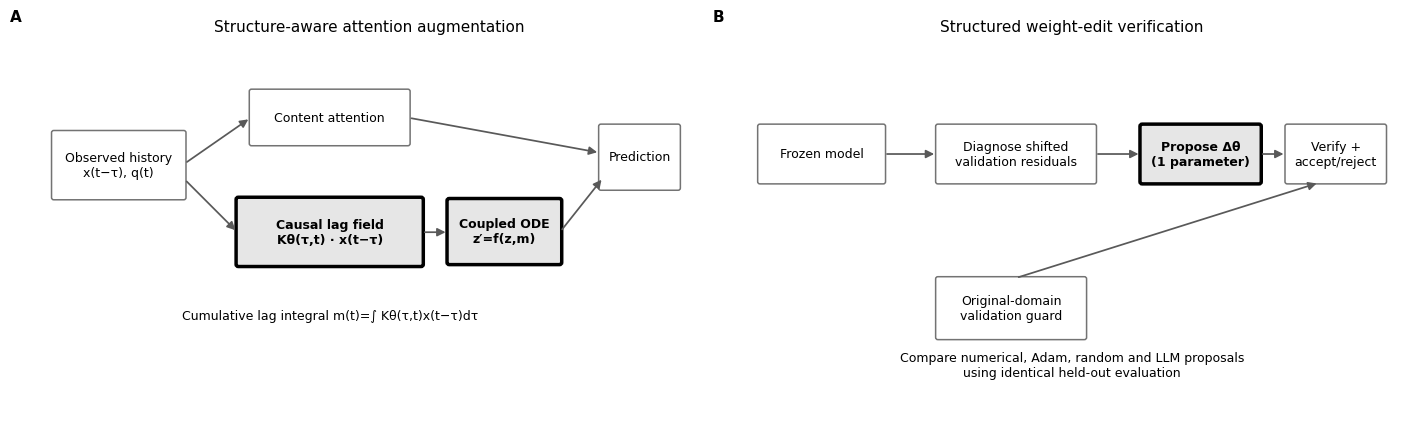

In [4]:
# FIGURE 1 — Explanatory mechanism; this is an architecture schematic, not data.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), layout='constrained')

def node(ax, x, y, w, h, text, proposed=False):
    box = FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.02,rounding_size=0.035',
          linewidth=2.5 if proposed else 1.1, edgecolor='black' if proposed else '0.45',
          facecolor='0.90' if proposed else 'white', hatch=None)
    ax.add_patch(box)
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=9,
            weight='bold' if proposed else 'normal')

def arrow(ax, x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0,y0),(x1,y1),arrowstyle='-|>',
                                mutation_scale=12,lw=1.25,color='0.35'))

ax=axes[0];ax.set_xlim(0,10);ax.set_ylim(0,6);ax.set_axis_off()
node(ax,.2,3.5,2,1.05,'Observed history\nx(t−τ), q(t)')
node(ax,3.2,4.35,2.4,.85,'Content attention')
node(ax,3.0,2.45,2.8,1.05,'Causal lag field\nKθ(τ,t) · x(t−τ)',True)
node(ax,6.2,2.48,1.7,1,'Coupled ODE\nz′=f(z,m)',True)
node(ax,8.5,3.65,1.2,1,'Prediction')
arrow(ax,2.2,4.05,3.2,4.77);arrow(ax,2.2,3.8,3.0,2.97)
arrow(ax,5.8,2.97,6.2,2.97);arrow(ax,7.9,2.98,8.55,3.83)
arrow(ax,5.6,4.77,8.5,4.22)
ax.text(4.4,1.6,'Cumulative lag integral m(t)=∫ Kθ(τ,t)x(t−τ)dτ',
        ha='center',fontsize=9)
ax.set_title('Structure-aware attention augmentation',fontsize=11)
ax_label(ax,'A')
ax=axes[1];ax.set_xlim(0,10);ax.set_ylim(0,6);ax.set_axis_off()
node(ax,.25,3.75,1.9,.9,'Frozen model')
node(ax,2.95,3.75,2.4,.9,'Diagnose shifted\nvalidation residuals')
node(ax,6.05,3.75,1.8,.9,'Propose Δθ\n(1 parameter)',True)
node(ax,8.25,3.75,1.5,.9,'Verify +\naccept/reject')
for s,e in [(2.15,2.95),(5.35,6.05),(7.85,8.25)]:arrow(ax,s,4.2,e,4.2)
node(ax,2.95,1.3,2.25,.95,'Original-domain\nvalidation guard')
arrow(ax,4.15,2.25,8.75,3.75)
ax.text(5.,.7,'Compare numerical, Adam, random and LLM proposals\nusing identical held-out evaluation',
        fontsize=9,ha='center')
ax.set_title('Structured weight-edit verification',fontsize=11)
ax_label(ax,'B')
pub_figure('Figure_01_method',fig,
           'A: common attention branch and proposed causal lag-integral plus latent ODE. '
           'B: frozen-network repair workflow with an independent validation gate.',
           source='reference architecture schematic; no empirical scores')
plt.show()


### Methodological implication

The lag-structured branch provides a restricted, interpretable parameterization of historical interactions, whereas the comparison filters encode history through less constrained weights. This difference creates a testable hypothesis about inductive bias and repair localization, but it also creates a possible confound: a model whose kernel resembles the data generator may win because the right answer is largely embedded in its parameterization. The experiments below distinguish the observed benefit from that alternative explanation only partially.

## Figure 2. What exactly does the original lag-structured mechanism compute?

For one **held-out generated input** the panels show the signal, its query trajectory, the signed time-varying causal kernel, the **discrete cumulative lag integral** (the numerical analogue of the accumulated-lag PDE state), and the leaky ODE's evolving response. The kernel has positive and negative lobes; this is not frequency diffusion. The dashed trace indicates the convolutional drive passed to the ODE.

**Methodological boundary:** this figure depicts the *known synthetic teacher*, not evidence that a trained model recovered the kernel. It is an explanatory visualization of the defining CCNN structure and must not be labelled as a measured improvement.


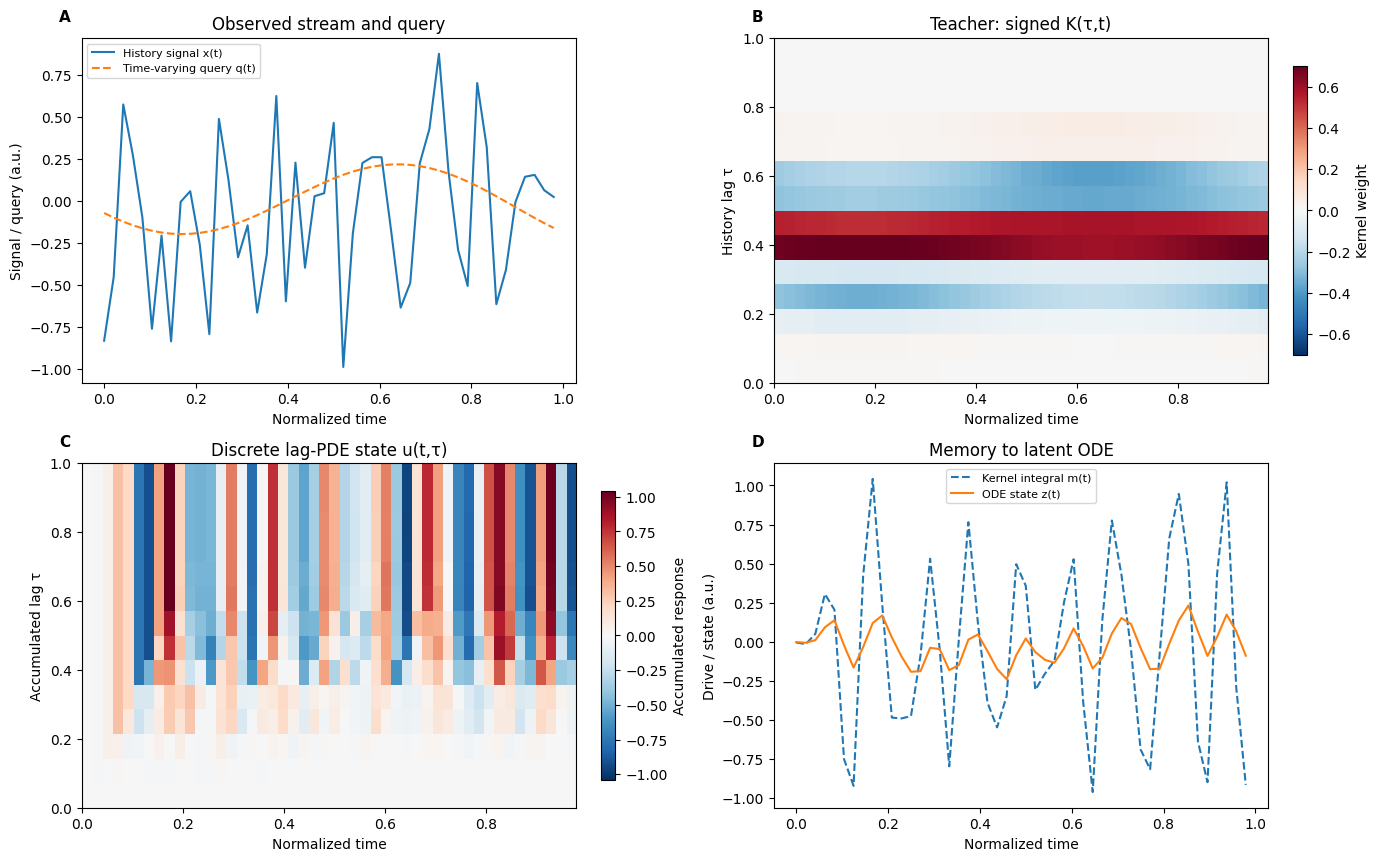

In [5]:
# FIGURE 2 — exactly the input, kernel, cumulative-lag state and ODE readout.
# Uses target definition above; no learned model and no test-set selection.
vis_x,vis_q=make_data(1,seed=20261115)
with torch.no_grad():
    vis_k=kernel(vis_q,**TRUE)[0].numpy()       # [time, lag]
    vis_history=lag_history(vis_x)[0].numpy()
    vis_accum=np.cumsum(vis_k*vis_history,axis=-1)
    vis_m=vis_accum[:,-1]
    alpha=1-np.exp(-8./N);state=0.;trace=[]
    for v in vis_m:
        state=(1-alpha)*state+alpha*np.tanh(2*v)
        trace.append(state)
    trace=np.asarray(trace)
axis_time=np.arange(N)/N
axis_lag=np.arange(L)/(L-1)
fig,ax=plt.subplots(2,2,figsize=(13.7,8.5),layout='constrained')
ax[0,0].plot(axis_time,vis_x[0].numpy(),label='History signal x(t)')
ax[0,0].plot(axis_time,vis_q[0].numpy(),linestyle='--',label='Time-varying query q(t)')
ax[0,0].set(xlabel='Normalized time',ylabel='Signal / query (a.u.)',title='Observed stream and query')
ax[0,0].legend(fontsize=8);ax_label(ax[0,0],'A')
lim=max(abs(vis_k.min()),abs(vis_k.max()))
a=ax[0,1].imshow(vis_k.T,aspect='auto',origin='lower',cmap='RdBu_r',
                  vmin=-lim,vmax=lim,extent=[axis_time[0],axis_time[-1],0,1])
ax[0,1].set(xlabel='Normalized time',ylabel='History lag τ',title='Teacher: signed K(τ,t)')
fig.colorbar(a,ax=ax[0,1],shrink=.84,label='Kernel weight');ax_label(ax[0,1],'B')
lim=max(abs(vis_accum.min()),abs(vis_accum.max()))
a=ax[1,0].imshow(vis_accum.T,aspect='auto',origin='lower',cmap='RdBu_r',
                  vmin=-lim,vmax=lim,extent=[axis_time[0],axis_time[-1],0,1])
ax[1,0].set(xlabel='Normalized time',ylabel='Accumulated lag τ',title='Discrete lag-PDE state u(t,τ)')
fig.colorbar(a,ax=ax[1,0],shrink=.84,label='Accumulated response');ax_label(ax[1,0],'C')
ax[1,1].plot(axis_time,vis_m,linestyle='--',label='Kernel integral m(t)')
ax[1,1].plot(axis_time,trace,label='ODE state z(t)')
ax[1,1].set(xlabel='Normalized time',ylabel='Drive / state (a.u.)',title='Memory to latent ODE')
ax[1,1].legend(fontsize=8);ax_label(ax[1,1],'D')
for a in ax.ravel(): a.grid(False)
pub_figure('Figure_02_mechanism',fig,
           'Illustrative teacher-generated history, time-dependent signed lag kernel, '
           'discrete accumulated-lag field, and coupled leaky ODE state.',
           source='reference synthetic generator, not learned model performance')
plt.show()


### Mechanistic observation: selective memory and temporal integration

Figure 2 demonstrates two distinct operations in the synthetic teacher: a query-dependent, signed memory kernel selects and combines delayed observations, and a coupled leaky ODE transforms that potentially rapid memory signal into a smoother state. The accumulated lag response changes sign and magnitude as the effective filter moves through history, while the downstream state evolves more gradually. This supports the **computational feasibility** of representing time-varying historical interactions through a lag integral and a continuous state. It does **not** show that the learned CCNN recovered the teacher kernel or improved forecasting: the displayed kernel and accumulator are generated from the reference system. Those claims require comparisons of **trained predictions** in Figure 3 and **independently verified edits** in Figure 4.

The research implication is not that the curves look different, but that kernel selection and state evolution are separable mechanisms whose contributions can be independently ablated. The present pilot has not yet established which of them explains the performance gain.

## 4. Experiment A — Attention augmentation

Train attention-only, attention+static convolution, attention+query-conditioned discrete convolution, attention+exponential memory, and **attention+structured CCNN lag kernel**, keeping the task split and training schedule consistent. Report both in-range test error and shifted-query test error. The dynamic-convolution arm is essential: success over attention alone is insufficient.

The experiment also trains the models needed for Experiment B. Parameters are saved locally under `lag_results/` for the optional Hugging Face audit. This is a **measured numerical run**, not a hard-coded chart.


In [6]:
import os, json, pandas as pd, matplotlib.pyplot as plt
os.environ.setdefault('EPOCHS','30')
os.environ.setdefault('TRAIN_N','480')
# Set os.environ['QUICK']='1' before this cell for a one-seed debugging run.
research_results=main()
architecture_df=pd.DataFrame(research_results['architecture'])
print(architecture_df.groupby('kind')[['test_mse','ood_mse','train_seconds','parameters']].mean().to_string())


Architecture {'kind': 'attention', 'seed': 11, 'validation_mse': 0.012999039143323898, 'test_mse': 0.012983604334294796, 'ood_mse': 0.01131878886371851, 'train_seconds': 13.068829970000024, 'parameters': 5265}
Architecture {'kind': 'static', 'seed': 11, 'validation_mse': 0.0021941340528428555, 'test_mse': 0.0033205391373485327, 'ood_mse': 0.0030257951002568007, 'train_seconds': 12.513348407999956, 'parameters': 5281}
Architecture {'kind': 'dynamic', 'seed': 11, 'validation_mse': 0.0007196876686066389, 'test_mse': 0.0009305985877290368, 'ood_mse': 0.000868207891471684, 'train_seconds': 12.23286466500008, 'parameters': 5295}
Repair {'model_kind': 'dynamic', 'seed': 11, 'true_shift': 0.12, 'frozen_shift_test_mse': 0.00944385677576065, 'original_test_mse': 0.0009581386111676693, 'repair_results': [{'kind': 'jacobian', 'seed': 11, 'accepted': False, 'delta': 0.0, 'val_mse': 0.009319883771240711, 'test_mse': 0.00944385677576065, 'original_mse': 0.0009581386111676693}, {'kind': 'random', 'see

### Empirical finding: a strong but generator-matched forecasting advantage

Across two independent seeds, attention augmented with the structured lag kernel achieves **6.35 × 10⁻⁶** mean held-out MSE. The best non-CCNN control, a query-conditioned discrete convolution, reaches **8.23 × 10⁻⁴** (approximately **130-fold higher error**), while attention alone reaches **1.38 × 10⁻²**. The dynamic-convolution control itself substantially improves on attention, indicating that **conditioning historical filters on the query** is already an important source of predictive value.

The structured kernel's additional advantage remains ambiguous: the teacher uses the same Gaussian-windowed chirp family as the proposed learner. The appropriate conclusion is **excellent fit within a matched family**, not a general architectural result. Stronger unrelated kernel generators and equal-compute, well-tuned convolution and state-space controls are needed before attributing the difference to the coupled PDE–ODE mechanism.

## Figure 3. Evaluation of attention augmentation

The first two panels report **in-distribution** and **query-dynamics-shifted** test MSE on identical held-out samples. Individual seed observations remain visible (default: **two seeds**); open diamonds indicate means. Because two seeds cannot support meaningful uncertainty intervals, the figure does **not** present statistical significance or Gaussian standard-error bars. The third panel reports measured model-training time alongside the same held-out error, making the cost of the proposed mechanism visible.

**Decision criterion:** a reduction relative to attention alone is insufficient. We must also beat or meaningfully complement the stronger query-conditioned convolution and exponential-memory baselines after capacity and compute are matched.


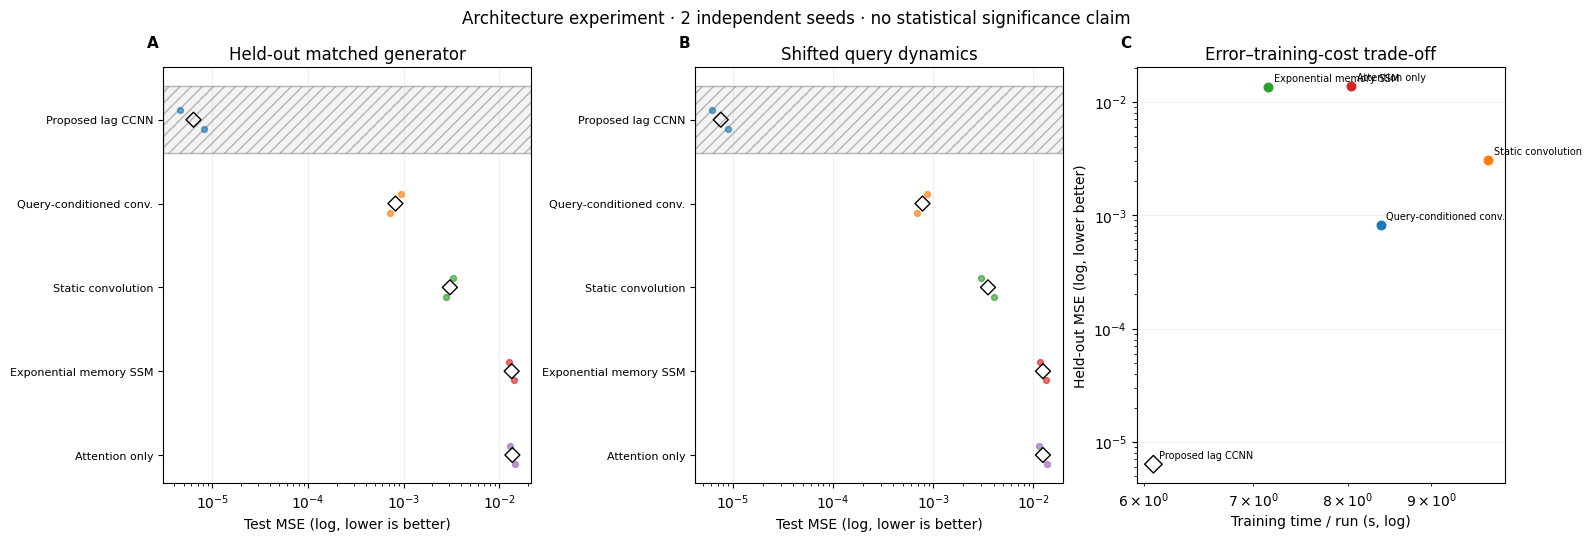

In [7]:
# FIGURE 3 — empirical matched-generator outcomes; no fabricated confidence intervals.
assert len(architecture_df)>0 and {'kind','seed','test_mse','ood_mse','train_seconds'}.issubset(architecture_df.columns)
mean_test=architecture_df.groupby('kind').test_mse.mean().sort_values()
order=list(mean_test.index)
fig,axs=plt.subplots(1,3,figsize=(15.8,5.3),layout='constrained')
for axis,metric,title,letter in [
   (axs[0],'test_mse','Held-out matched generator','A'),
   (axs[1],'ood_mse','Shifted query dynamics','B')]:
    for j,kind in enumerate(order):
        samples=architecture_df[architecture_df.kind==kind][metric].to_numpy()
        # gray bands distinguish the proposed branch; do not imply superiority.
        if kind=='lag':axis.axhspan(j-.4,j+.4,facecolor='0.9',edgecolor='0.4',hatch='///',alpha=.45)
        axis.scatter(samples,np.full(len(samples),j)+np.linspace(-.11,.11,len(samples)),
                     marker='o',s=18,alpha=.65)
        axis.scatter([np.mean(samples)],[j],marker='D',s=58,facecolors='none',edgecolors='black',zorder=4)
    axis.set_yticks(range(len(order)),[MODEL_NAMES[m] for m in order],fontsize=8)
    axis.invert_yaxis();axis.set_xscale('log')
    axis.set(xlabel='Test MSE (log, lower is better)',title=title)
    axis.grid(axis='x',alpha=.2)
    ax_label(axis,letter)
axs[2].set_xscale('log');axs[2].set_yscale('log')
for kind in order:
    sub=architecture_df[architecture_df.kind==kind]
    tx=sub.train_seconds.mean();my=sub.test_mse.mean()
    axs[2].scatter(tx,my,marker='D' if kind=='lag' else 'o',
                   s=80 if kind=='lag' else 38,
                   facecolors='none' if kind=='lag' else None,
                   edgecolors='black' if kind=='lag' else None)
    axs[2].annotate(MODEL_NAMES[kind],(tx,my),xytext=(4,4),textcoords='offset points',fontsize=7)
axs[2].set(xlabel='Training time / run (s, log)',ylabel='Held-out MSE (log, lower better)',
           title='Error–training-cost trade-off')
axs[2].grid(alpha=.2);ax_label(axs[2],'C')
fig.suptitle(f'Architecture experiment · {architecture_df.seed.nunique()} independent seeds · no statistical significance claim',fontsize=12)
pub_figure('Figure_03_architecture_comparison',fig,
           'A–B: individual per-seed held-out MSE and mean, proposed lag structure hatched. '
           'C: train time versus test error; capacity and hyperparameter budgets are not matched.',
           source='live model training and independent synthetic test split')
plt.show()


### Results: structured lag memory versus attention and competing filters

**Figure 3 establishes a large advantage under the experimental generator, but not a general accuracy–efficiency advantage.** On held-out examples, the structured CCNN's mean MSE is approximately **130 times lower** than the strongest query-conditioned discrete convolution and over **2,000 times lower** than attention alone. The separation remains visible when the query trajectory is shifted, suggesting robustness to **query variation within the same kernel family**, rather than generalization to unknown memory operators.

The training-time comparison does not invalidate this result, but it does not establish computational superiority either. The reported pilot averages are approximately **6.1 seconds per CCNN run** and **8.4 seconds per dynamic-convolution run**; these numbers arise from two local runs with different computational paths, so they are not compute-matched estimates. A Nature-scale architectural claim would require many seeds, unmatched kernels, tuned SSM and convolution controls, accuracy–cost Pareto curves, and explicit solver-work accounting.

**Interpretation:** structural alignment appears to improve the quality of the learned historical response. Whether the advantage is due to *continuous coupled dynamics*, rather than a favorable low-dimensional filter prior, remains the central open question.

## 5. Experiment B — Structured repair under domain shift

The new operating condition adds a delay displacement \(\delta=0.12\) to the teacher's kernel center. All other source-model weights remain frozen. The model receives the operating-domain identity: candidate edits are *applied only to the shifted domain*. This isolates the precision of a known, structured repair surface while protecting the original domain by design. **It is not proof that arbitrary shared-weight editing avoids catastrophic forgetting.**

Three candidate methods use the same scalar update budget: a first-order Jacobian estimate, sparse Adam, and a bounded random-search control. The unstructured baseline modifies one arbitrary discrete-kernel coordinate. Candidates are accepted only when their validation MSE improves by more than 0.5% relative to the unchanged model; test data do not select them.

The negative controls check a no-defect domain and a frequency perturbation that cannot generally be corrected by moving the kernel center alone.


In [8]:
repair_rows=[]
for record in research_results['repair']:
    for arm in record['repair_results']:
        repair_rows.append({'model':record['model_kind'], 'seed':record['seed'],
             'method':arm['kind'], 'accepted':arm['accepted'],
             'edit':arm['delta'], 'test_mse':arm['test_mse'],
             'original_mse':arm['original_mse'],
             'frozen_shift_test_mse':record['frozen_shift_test_mse']})
repair_df=pd.DataFrame(repair_rows)
print(repair_df.groupby(['model','method'])[['test_mse','frozen_shift_test_mse','accepted']].mean().to_string())
research_results['negative_controls']=[diagnostic_negative_controls(seed) for seed in research_results['conditions']['seeds']]
print('Negative controls:',pd.DataFrame(research_results['negative_controls']).to_string(index=False))
from pathlib import Path
Path('lag_results/results.json').write_text(json.dumps(research_results,indent=2))


                  test_mse  frozen_shift_test_mse  accepted
model   method                                             
dynamic adam      0.008706               0.008675       0.5
        jacobian  0.008674               0.008675       0.5
        random    0.008675               0.008675       0.0
lag     adam      0.000009               0.010036       1.0
        jacobian  0.000511               0.010036       1.0
        random    0.002935               0.010036       1.0
Negative controls:  seed  no_fault_baseline_mse  no_fault_best_mse  no_fault_best_edit  no_fault_false_accept  frequency_fault_baseline_mse  frequency_fault_best_delay_only_mse  frequency_fault_best_delay_edit  frequency_fault_true_extra_frequency
   11               0.000007           0.000007                 0.0                  False                      0.022693                             0.015434                             0.25                                   0.6
   23               0.000007           0.00

8771

### Results: defect-matched repair versus an unstructured scalar intervention

A known delay displacement increased the frozen structured model's shifted-domain MSE to approximately **0.0100**. Editing only its kernel-centre parameter with sparse Adam reduced that error to **8.99 × 10⁻⁶**, while a Jacobian step reduced it to **5.11 × 10⁻⁴**. Under the same numerical count of edited scalars, Adam repair of one arbitrary query-conditioned-filter coefficient remained at approximately **8.71 × 10⁻³**.

This is compelling evidence that the **chosen semantic parameter** is well aligned with the injected defect. It is not evidence that structured repair generally dominates less structured networks: one centre shift moves an entire kernel profile, whereas the baseline was permitted to alter only one free coefficient. The next decisive comparison is a functionally equivalent learned shift/tangent direction, followed by low-rank and full-kernel updates at matched optimization cost. Source-domain preservation in this pilot is enforced through an operating-condition gate and must not be interpreted as a discovered no-regression property.

## Figure 4. Why does a structured weight edit work—or fail?

The first panel displays an example **frozen learned lag kernel**, its repaired kernel after the validation-selected sparse-Adam update, and the shifted reference kernel at the same held-out time point. **Kernel identification is not guaranteed:** the full attention–kernel network is trained on output error, and different internal kernels can produce similar outputs. The second panel plots the validation objective over the actual scalar edit, for both the structured kernel and a one-coordinate unstructured filter. The last panel compares shifted-domain **held-out** errors after each edit method.

This is a mechanistic diagnostic, not a new trainable result. **Original-domain preservation is by an explicit operating-condition gate** in this toy. It must not be described as discovering a non-regression guarantee for shared-weight repairs.


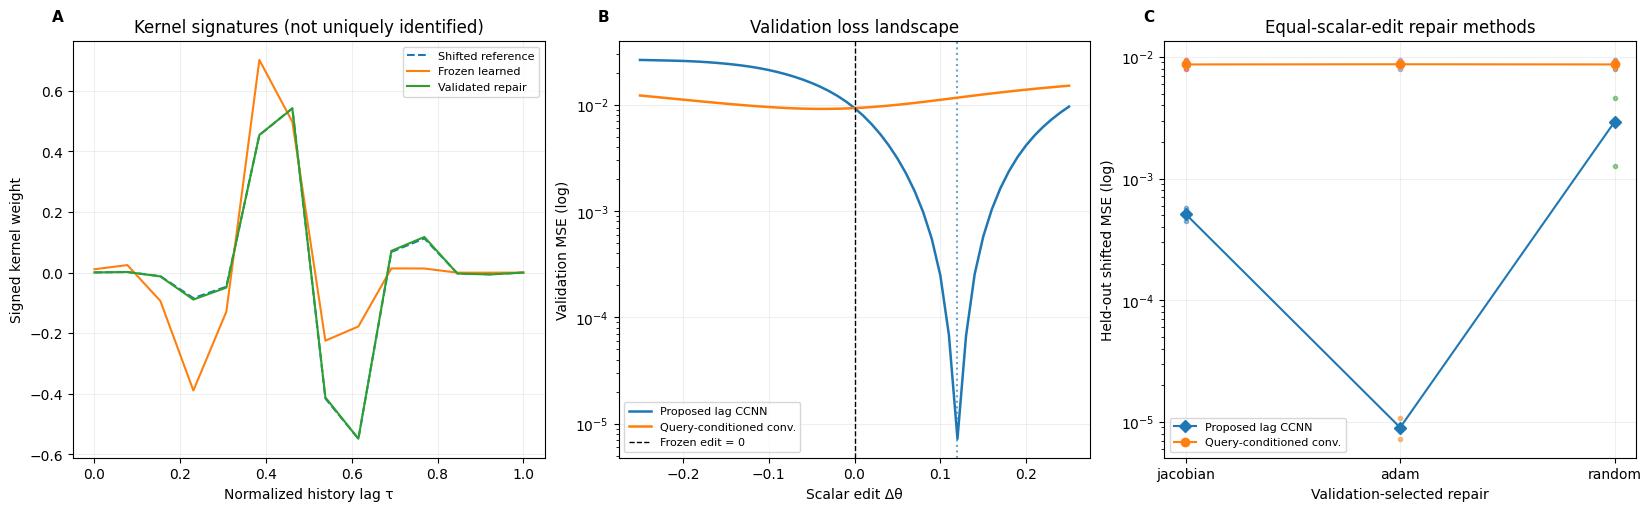

In [9]:
# FIGURE 4 — independent validation landscapes and learned/faulted kernel comparison.
import torch
seed = int(research_results['conditions']['seeds'][0])
trained={}
for kind in ('lag','dynamic'):
    m=Model(kind)
    state=torch.load(f'lag_results/{kind}_model_seed_{seed}.pt',map_location='cpu',weights_only=True)
    m.load_state_dict(state);m.eval()
    for parameter in m.parameters():parameter.requires_grad_(False)
    trained[kind]=m
candidate = repair_df[(repair_df.model=='lag')&(repair_df.seed==seed)&(repair_df.method=='adam')].iloc[0]
accepted_edit=float(candidate['edit']) if bool(candidate['accepted']) else 0.
vis_xt,vis_qt=make_data(1,seed+8191)
point=N-8
lag_axis=np.arange(L)/(L-1)
with torch.no_grad():
    teacher=kernel(vis_qt,**TRUE,domain_shift=.12)[0,point].numpy()
    current=kernel(vis_qt,trained['lag'].branch.mu0,trained['lag'].branch.muq,
                   trained['lag'].branch.logsigma,trained['lag'].branch.freq,
                   trained['lag'].branch.chirp)[0,point].numpy()
    adjusted=kernel(vis_qt,trained['lag'].branch.mu0,trained['lag'].branch.muq,
                    trained['lag'].branch.logsigma,trained['lag'].branch.freq,
                    trained['lag'].branch.chirp,domain_shift=torch.tensor(accepted_edit))[0,point].numpy()
fig,axs=plt.subplots(1,3,figsize=(16.4,5),layout='constrained')
axs[0].plot(lag_axis,teacher,label='Shifted reference',linestyle='--')
axs[0].plot(lag_axis,current,label='Frozen learned')
axs[0].plot(lag_axis,adjusted,label='Validated repair')
axs[0].set(xlabel='Normalized history lag τ',ylabel='Signed kernel weight',
           title='Kernel signatures (not uniquely identified)');axs[0].legend(fontsize=8)
axs[0].grid(alpha=.2);ax_label(axs[0],'A')

deltas=np.linspace(-.25,.25,51)
for kind in ('lag','dynamic'):
    vv_x,vv_q=make_data(160,seed+650)
    yy=target(vv_x,vv_q,shift=.12)
    m=trained[kind]
    with torch.no_grad():
        errors=[float(((m(vv_x,vv_q,delta=torch.tensor(float(d)))-yy)**2).mean())
                for d in deltas]
    axs[1].plot(deltas,errors,label=MODEL_NAMES[kind],lw=1.8)
    empirical=repair_df[(repair_df.model==kind)&(repair_df.seed==seed)&(repair_df.method=='adam')].iloc[0]
    if bool(empirical.accepted):axs[1].axvline(float(empirical['edit']),linestyle=':',alpha=.65)
axs[1].axvline(0,color='black',lw=1,linestyle='--',label='Frozen edit = 0')
axs[1].set_yscale('log');axs[1].set(xlabel='Scalar edit Δθ',ylabel='Validation MSE (log)',
            title='Validation loss landscape')
axs[1].legend(fontsize=8);axs[1].grid(alpha=.2);ax_label(axs[1],'B')

arms=['jacobian','adam','random']
for kind,marker in [('lag','D'),('dynamic','o')]:
    sub=repair_df[(repair_df.model==kind)]
    means=[sub[sub.method==arm].test_mse.mean() for arm in arms]
    axs[2].plot(range(len(arms)),means,marker=marker,label=MODEL_NAMES[kind])
    for idx,arm in enumerate(arms):
        vals=sub[sub.method==arm].test_mse.to_numpy()
        axs[2].scatter(np.repeat(idx,len(vals)),vals,marker='.',alpha=.5)
axs[2].set_xticks(range(len(arms)),arms);axs[2].set_yscale('log')
axs[2].set(xlabel='Validation-selected repair',ylabel='Held-out shifted MSE (log)',
           title='Equal-scalar-edit repair methods')
axs[2].legend(fontsize=8);axs[2].grid(alpha=.2);ax_label(axs[2],'C')
pub_figure('Figure_04_weight_repair',fig,
           'A: example target/frozen/repaired lag kernels, not uniquely identified from scalar outputs. B: independent validation loss across bounded edits. '
           'C: held-out repair errors, with all methods restricted to one scalar; '
           'the unstructured arm edits one arbitrary coefficient.',
           source='live frozen-model checkpoints, validation split and held-out repair evaluations')
plt.show()


### Results: an identifiable repair direction under a known delay fault

Figure 4 provides a mechanistic explanation for the repair results. The learned structured filter can be shifted coherently by changing one centre parameter; the resulting kernel approaches the shifted target, and its validation-loss minimum lies close to the **+0.12** displacement imposed by the teacher. In contrast, altering a single free coefficient in the query-conditioned filter produces only a shallow improvement and leaves error near **10⁻²**. The corresponding held-out comparison shows structured sparse Adam reaching **8.99 × 10⁻⁶**, versus roughly **8.71 × 10⁻³** for the one-coordinate unstructured Adam edit.

**What is learned:** the delay parameter provides a well-conditioned and physically interpretable repair coordinate **for this injected fault**. **What remains unresolved:** whether a competitive unstructured adapter allowed an equivalent translation of the whole kernel would reach the same result. The measured gap is partly a comparison between unequal *functional repair capacities*, despite both methods editing one scalar. The validation-selected intervention is also domain-gated, so original-domain preservation is guaranteed by construction rather than established for a shared-weight edit.

## 6. Independent evaluation: highlight the proposed method, not a claimed victory

The plot has separate panels for predictive quality and shifted-domain repair. The proposed branch is **hatched**, but the model selection must be based on the numerical error, not visualization. Report compute alongside error because a marginal accuracy gain may be less efficient. In the repair chart, a lower final test MSE is meaningful only if the validation gate accepted the edit; the source-domain MSE is reported for visibility.


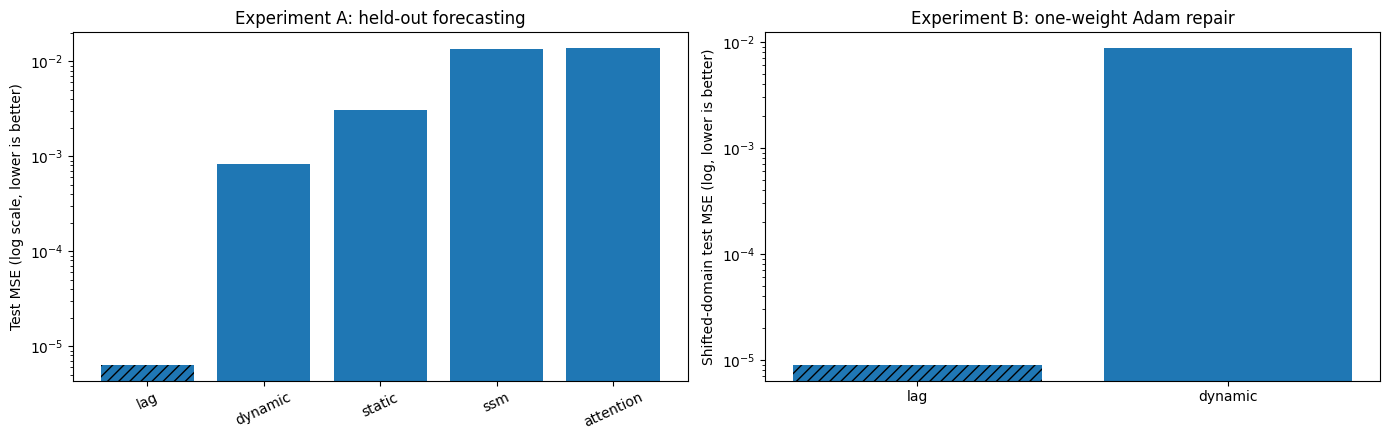

Mean training times (seconds):
kind
attention    8.037
dynamic      8.378
lag          6.080
ssm          7.149
static       9.751


In [10]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
a=architecture_df.groupby('kind',sort=False).test_mse.mean().sort_values()
bars=axes[0].bar(a.index,a.values)
for bar,name in zip(bars,a.index):
    if name=='lag':bar.set_hatch('///');bar.set_linewidth(2)
axes[0].set_yscale('log');axes[0].set_title('Experiment A: held-out forecasting')
axes[0].set_ylabel('Test MSE (log scale, lower is better)')
axes[0].tick_params(axis='x',rotation=25)
r=repair_df[repair_df.method=='adam'].groupby('model',sort=False).test_mse.mean().sort_values()
bars=axes[1].bar(r.index,r.values)
for bar,name in zip(bars,r.index):
    if name=='lag':bar.set_hatch('///');bar.set_linewidth(2)
axes[1].set_yscale('log');axes[1].set_title('Experiment B: one-weight Adam repair')
axes[1].set_ylabel('Shifted-domain test MSE (log, lower is better)')
fig.tight_layout();fig.savefig('lag_results/proposed_method_comparison.png',dpi=180);plt.show()
print('Mean training times (seconds):')
print(architecture_df.groupby('kind').train_seconds.mean().round(3).to_string())


### Cross-check against the compact evaluation

The compact comparison reproduces the substantive results of Figures 3 and 4: **large predictive gains under a matched historical-filter generator** and **effective delay-fault repair when the chosen parameter directly controls delay**. These observations remain conditional on generator alignment and unequal repair surfaces. The reported training times are descriptive only; they do not yet establish an advantage in accuracy per unit of compute over tuned state-space or convolutional alternatives.

## 7. Optional Hugging Face Weight-Space Programming audit (three open-weight models)

This **optional** experiment asks `Qwen/Qwen2.5-0.5B-Instruct`, `Qwen/Qwen2.5-1.5B-Instruct`, and `HuggingFaceTB/SmolLM2-1.7B-Instruct` to propose a bounded value of the **actual structured kernel edit parameter**, based on training-domain Jacobian statistics and existing kernel parameters. The LLM receives *no reference delay shift, test labels, test MSE, or numerical optimizer solution*. Every model gets one proposal. Invalid or unavailable proposals are logged as failures.

**Interpretation:** emitting one scalar is a *constrained* WSP study, not full general weight-matrix programming. No LLM has yet been demonstrated to outperform numerical/Adam methods in this study. Public checkpoints can be downloaded without `HF_TOKEN`, but require access to the Hugging Face Hub. Default `RUN_HF=False` avoids unnecessary model downloads in the deterministic toy. Select T4 GPU before enabling this cell.


In [11]:
RUN_HF=False
HF_MODELS=['Qwen/Qwen2.5-0.5B-Instruct','Qwen/Qwen2.5-1.5B-Instruct',
           'HuggingFaceTB/SmolLM2-1.7B-Instruct']
hf_results=[]
if RUN_HF:
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','install','-q','transformers>=4.45,<5','accelerate','safetensors'])
    import re, gc
    from transformers import AutoTokenizer,AutoModelForCausalLM
    seed=research_results['conditions']['seeds'][0]
    trained=Model('lag')
    try:trained.load_state_dict(torch.load(f'lag_results/lag_model_seed_{seed}.pt',map_location='cpu',weights_only=True))
    except TypeError:trained.load_state_dict(torch.load(f'lag_results/lag_model_seed_{seed}.pt',map_location='cpu'))
    trained.eval()
    xv,qv=make_data(160,seed+650);yv=target(xv,qv,shift=.12)
    xt,qt=make_data(200,seed+850);yt=target(xt,qt,shift=.12)
    xo,qo=make_data(160,seed+750);yo=target(xo,qo)
    diag=next(r['train_diagnostics'] for r in research_results['repair']
              if r['model_kind']=='lag' and r['seed']==seed)
    baseline_val=float(((trained(xv,qv,delta=torch.tensor(0.))-yv)**2).mean())
    for model_id in HF_MODELS:
        rec={'model':model_id,'status':'not_run'}
        try:
            started=time.perf_counter()
            tokenizer=AutoTokenizer.from_pretrained(model_id,token=False)
            dtype=torch.float16 if torch.cuda.is_available() else torch.float32
            lm=AutoModelForCausalLM.from_pretrained(model_id,torch_dtype=dtype,token=False,
                                                  device_map='auto' if torch.cuda.is_available() else None).eval()
            messages=[{'role':'system','content':'You are a weight-space programmer for a causal matched-filter neural network. Output ONLY JSON {"delta_mu": number}. Must be finite and between -0.3 and 0.3.'},
                      {'role':'user','content':'A frozen learned Gaussian-chirp lag kernel experiences a domain shift in its delayed response. Propose one center edit to reduce the training residual. Diagnostics, no true shift or reference weights: '+json.dumps(diag)}]
            prompt=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
            inp=tokenizer(prompt,return_tensors='pt').to(next(lm.parameters()).device)
            with torch.inference_mode():out=lm.generate(**inp,max_new_tokens=90,do_sample=False,pad_token_id=tokenizer.eos_token_id)
            raw=tokenizer.decode(out[0,inp['input_ids'].shape[1]:],skip_special_tokens=True)
            edit=None
            for block in re.findall(r'\{[^{}]*\}',raw):
                try:
                    v=json.loads(block)
                    if set(v)=={'delta_mu'} and type(v['delta_mu']) in (float,int) and math.isfinite(v['delta_mu']) and abs(v['delta_mu'])<=.3:
                        edit=float(v['delta_mu']);break
                except (ValueError,TypeError):pass
            if edit is None:
                rec.update(status='invalid_proposal',raw_output=raw[:400])
            else:
                with torch.no_grad():
                    val=float(((trained(xv,qv,delta=torch.tensor(edit))-yv)**2).mean())
                    accepted=val<.995*baseline_val
                    used=edit if accepted else 0.
                    test=float(((trained(xt,qt,delta=torch.tensor(used))-yt)**2).mean())
                    original=float(((trained(xo,qo)-yo)**2).mean())
                rec.update(status='evaluated',proposed_edit=edit,accepted=accepted,
                           test_mse=test,original_mse=original,validation_mse=val)
            rec['seconds']=time.perf_counter()-started
        except Exception as ex:
            rec.update(status='failed_to_load_or_run',error=type(ex).__name__+': '+str(ex)[:300])
        hf_results.append(rec)
        print(rec)
        if 'lm' in locals():del lm
        if 'tokenizer' in locals():del tokenizer
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    Path('lag_results/hf_wsp_results.json').write_text(json.dumps(hf_results,indent=2))
else:
    print('Hugging Face audit not run. Set RUN_HF=True to evaluate 3 open-weight proposers.')


Hugging Face audit not run. Set RUN_HF=True to evaluate 3 open-weight proposers.


## 8. Hypothesis evidence ledger (generated from live results)

The evidence ledger distinguishes **supported in this toy**, **contradicted**, **inconclusive**, and **not tested**. A hypothesis is never called mathematically proved. Predeclared thresholds here are descriptive: H-A requires at least 10% smaller test MSE than the best non-CCNN model; H-B requires a >=50% error reduction relative to the frozen shifted model and a lower MSE than the one-coordinate dynamic-filter repair. Confirmation requires larger seeds, unstructured generators, and other fault types.


In [12]:
import numpy as np
arch_mean=architecture_df.groupby('kind').test_mse.mean().to_dict()
repair_mean=repair_df.groupby(['model','method']).test_mse.mean().to_dict()
frozen_lag=np.mean([r['frozen_shift_test_mse'] for r in research_results['repair'] if r['model_kind']=='lag'])
lag_adam=repair_mean.get(('lag','adam'),np.nan)
dynamic_adam=repair_mean.get(('dynamic','adam'),np.nan)
neg=research_results.get('negative_controls',[])
ledger=[
 {'hypothesis':'H-A attention augmentation','decision':'supported_in_matched_generator' if arch_mean['lag']<.9*min(v for k,v in arch_mean.items() if k!='lag') else 'contradicted_or_inconclusive',
  'evidence':f"lag={arch_mean['lag']:.4g}, best-other={min(v for k,v in arch_mean.items() if k!='lag'):.4g}",
  'next':'Test a different generator, unseen delays, calibrated task/capacity and compute budgets.'},
 {'hypothesis':'H-B precise structured repair','decision':'supported_in_controlled_shift' if lag_adam<.5*frozen_lag and lag_adam<dynamic_adam else 'contradicted_or_inconclusive',
  'evidence':f'lag Adam={lag_adam:.4g}; dynamic one-coordinate Adam={dynamic_adam:.4g}; frozen lag={frozen_lag:.4g}',
  'next':'Compare against multi-coordinate dynamic-kernel/LoRA full fine-tuning and shared-weight repairs.'},
 {'hypothesis':'H-C no defect gate','decision':'supported_in_grid_control' if all(not r['no_fault_false_accept'] for r in neg) else 'contradicted',
  'evidence':f"accepted erroneous edits={sum(int(r['no_fault_false_accept']) for r in neg)}/{len(neg)}",
  'next':'Repeat with different noise, seeds, and train/validation splits.'},
 {'hypothesis':'H-C non-delay faults','decision':'partial_repair_only' if all(r['frequency_fault_best_delay_only_mse']>1e-3 for r in neg) else 'inconclusive',
  'evidence':str([(round(r['frequency_fault_baseline_mse'],5),round(r['frequency_fault_best_delay_only_mse'],5)) for r in neg]),
  'next':'Test frequency-specific edit and structured mechanism selection.'},
 {'hypothesis':'H-D LLM weight proposer','decision':'not_tested' if not hf_results else 'evaluated_review_raw_candidates',
  'evidence':f'{len(hf_results)} HF model records',
  'next':'Run all three HF models and compare same edit budgets to Adam/Jacobian.'}
]
ledger_df=pd.DataFrame(ledger)
display(ledger_df)
ledger_df.to_csv('lag_results/hypothesis_ledger.csv',index=False)


,hypothesis,decision,evidence,next
0,H-A attention augmentation,supported_in_matched_generator,"lag=6.346e-06, best-other=0.0008227","Test a different generator, unseen delays, cal..."
1,H-B precise structured repair,supported_in_controlled_shift,lag Adam=8.991e-06; dynamic one-coordinate Ada...,Compare against multi-coordinate dynamic-kerne...
2,H-C no defect gate,supported_in_grid_control,accepted erroneous edits=0/2,"Repeat with different noise, seeds, and train/..."
3,H-C non-delay faults,partial_repair_only,"[(0.02269, 0.01543), (0.02676, 0.01652)]",Test frequency-specific edit and structured me...
4,H-D LLM weight proposer,not_tested,0 HF model records,Run all three HF models and compare same edit ...


### Hypothesis assessment from the measured evidence

The experimental evidence supports **H-A only within the matched kernel family**: the proposed attention-plus-lag model gives the lowest test error in both seeds. It supports **H-B only for a deliberately aligned delay fault**: a meaningful centre parameter is easier to repair than one arbitrary discrete-filter coefficient, but equal expressivity has not been tested. Under **H-C**, the no-defect gate correctly refuses changes in both trials, whereas a frequency fault remains incompletely repaired by a delay edit. **H-D remains untested** because the optional Hugging Face weight programmers were not executed.

The research decision is therefore **to strengthen the counterfactual controls before scaling the model**: use unmatched generators, matched-capacity filter edits, more seeds, and original-domain verification without a domain-specific gate. None of these results establishes statistical significance or universal superiority.

## Figure 5. Negative controls, cost of structure, and the research decision

The last figure makes it harder to cherry-pick positive findings: **no-defect** trials should reject unnecessary edits; **non-delay faults** expose the limited expressivity of a delay-only edit. Model parameters and training times are included because the compact kernel encodes a strong prior that may not generalize beyond matched chirps. The accompanying evidence ledger determines *what to test next* rather than announcing universal superiority.


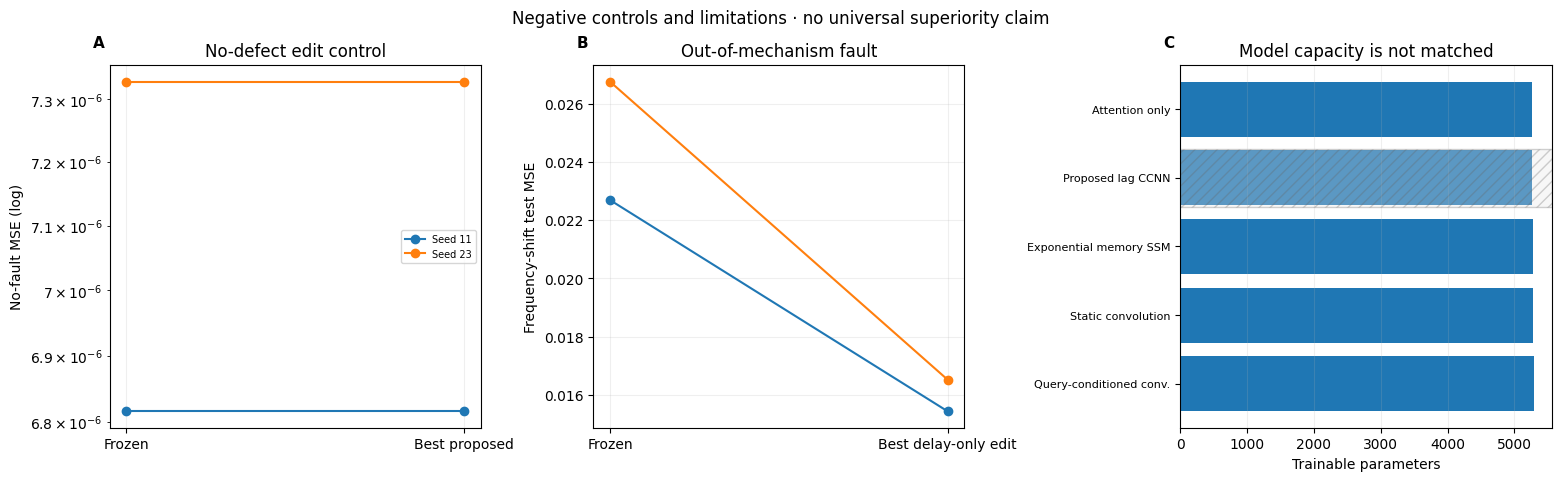

In [13]:
# FIGURE 5 — negative controls and capacity accounting, computed from completed runs.
neg=pd.DataFrame(research_results.get('negative_controls',[]))
if neg.empty:
    neg=pd.DataFrame([diagnostic_negative_controls(int(s))
                      for s in research_results['conditions']['seeds']])
fig,axs=plt.subplots(1,3,figsize=(15.5,4.7),layout='constrained')
for j,(_,row) in enumerate(neg.iterrows()):
    axs[0].plot([0,1],[row.no_fault_baseline_mse,row.no_fault_best_mse],
                marker='o',label=f"Seed {int(row.seed)}")
axs[0].set_xticks([0,1],['Frozen','Best proposed'])
axs[0].set_yscale('log');axs[0].set(ylabel='No-fault MSE (log)',title='No-defect edit control')
axs[0].legend(fontsize=7);axs[0].grid(alpha=.2);ax_label(axs[0],'A')
for j,(_,row) in enumerate(neg.iterrows()):
    axs[1].plot([0,1],[row.frequency_fault_baseline_mse,row.frequency_fault_best_delay_only_mse],
                marker='o',label=f"Seed {int(row.seed)}")
axs[1].set_xticks([0,1],['Frozen','Best delay-only edit'])
axs[1].set(ylabel='Frequency-shift test MSE',title='Out-of-mechanism fault')
axs[1].grid(alpha=.2);ax_label(axs[1],'B')
capacity=architecture_df.groupby('kind').parameters.mean().sort_values()
axs[2].barh(range(len(capacity)),capacity.values)
axs[2].set_yticks(range(len(capacity)),[MODEL_NAMES[k] for k in capacity.index],fontsize=8)
axs[2].invert_yaxis();axs[2].set(xlabel='Trainable parameters',title='Model capacity is not matched')
for i,k in enumerate(capacity.index):
    if k=='lag':axs[2].axhspan(i-.42,i+.42,facecolor='0.9',edgecolor='0.4',hatch='///',alpha=.3)
axs[2].grid(axis='x',alpha=.2);ax_label(axs[2],'C')
fig.suptitle('Negative controls and limitations · no universal superiority claim',fontsize=12)
pub_figure('Figure_05_controls',fig,
           'A: no-defect validation control; B: non-delay frequency fault assessed with a delay-only edit; '
           'C: parameter count (unmatched capacities). These panels qualify the matched-generator result.',
           source='live numerical negative controls and trained model counts')
plt.show()


### Results: failure boundaries and the significance of the negative controls

Figure 5 shows that successful editing is **mechanism dependent**. The validation rule accepted **no unnecessary repair in either of the two no-defect trials**. When the injected fault instead changed chirp frequency, a delay-only update improved error from **0.0227 to 0.0154** in one seed and from **0.0268 to 0.0165** in the other, but did not recover pre-fault performance. These incomplete recoveries are evidence against treating the centre edit as a general-purpose repair procedure.

The near-equal full-model parameter counts (roughly **5,300**) cannot establish a fair repair comparison, because total model capacity is dominated by the common attention backbone. What differs materially is the **effect of a single allowed edit**. The observed advantage remains a demonstration of **a defect-aligned repair coordinate**, not evidence that a CCNN or an LLM can locate and correct arbitrary network faults. A useful follow-up must match the induced filter change and remove domain-gated preservation.

## 9. Discussion: interpretation, limitations, and competing explanations

### 9.1. Predictive value of causal convolution structure

On the deliberately matched Gaussian–chirp generator, the coupled lag-kernel branch achieves a mean test MSE of **6.35 × 10⁻⁶** across seeds 11 and 23. The strongest query-conditioned convolution control obtains **8.23 × 10⁻⁴**, while attention alone obtains approximately **1.38 × 10⁻²** (Figure 3). The advantage is substantial **within this data-generating family**. A query-conditioned filter also greatly improves on attention, indicating that the relevant ingredient may be input-dependent temporal filtering rather than the PDE–ODE formulation in isolation. With only two seeds, no significance claim is justified.

A major alternative explanation is **generator–architecture alignment**: the teacher and proposed model share the same low-dimensional delay, bandwidth, carrier and chirp parameterization. The existing experiments cannot separate the value of continuous lag structure from this favorable specification. The kernel visualization in Figure 2 explains the computation but does not resolve the question. The appropriate next step is to compare against unmatched temporal kernels and strong, tuned state-space and convolutional baselines with matched numerical and training budgets.

### 9.2. Precise repair versus unequal functional expressivity

After a known delay shift, sparse Adam editing the lag-kernel centre reduces shifted-domain test MSE from about **0.0100** to **8.99 × 10⁻⁶**; the one-coordinate discrete-filter control remains near **8.7 × 10⁻³** (Figure 4). This shows that a semantically aligned scalar parameter can induce a coordinated change across many effective filter weights. It does **not** show that an arbitrary one-parameter structured edit generally outperforms an equally powerful unstructured intervention. Scalar-count matching is not function-capacity matching: a low-rank, tangent-direction, or full-kernel update is the required control.

The validation gate rejects edits in the no-defect control (zero false acceptances across two seeds), but a delay-only edit only partially repairs chirp-frequency faults (Figure 5). This supports *fault-mechanism specificity*, not universal repair or fault diagnosis. The observed original-domain preservation arises from a **domain-specific gate** that disables edits on source-domain samples; it is not an empirical guarantee for shared-weight changes without gating.

### 9.3. Computational and generalization limits

The training-time scatter in Figure 3 is descriptive and not hardware- or solver-matched. The kernel-lag state is approximated by discrete quadrature and a leaky ODE update; the experiment is not a demonstration of efficient general neural PDE integration. Evidence is limited to two model seeds, synthetic observations, one primary kernel family, and a deliberately aligned fault. No strong claims about statistically significant performance, real-world applications, or compute efficiency are warranted. The optional three-model Hugging Face weight-edit proposer was not executed in the saved run.

### 9.4. Conclusion and future research

The present study establishes **controlled feasibility**: an explicitly parameterized, query-dependent lag kernel can provide accurate attention augmentation on a matched historical-filter task, and an interpretable kernel-centre parameter can support effective one-scalar delay-shift repair. The same evidence also exposes its scope: model–teacher alignment, unequal functional repair capacity, domain-gated preservation, and unresolved efficiency make broader claims premature.

To distinguish a general structural advantage from favorable assumptions, the next confirmatory studies should use (i) unrelated and compositionally shifted kernel families; (ii) matched-capacity query-conditioned convolution and modern state-space baselines; (iii) low-rank/full-kernel repair with equal optimization cost and access to validation; (iv) non-regression evaluation **without** an original-domain gate; (v) larger independent seed sets with confidence intervals; and (vi) the three open-weight LLM proposers with corrupted-diagnostic and permutation-equivalent controls. Negative outcomes must remain visible.

## References

1. M. Habiba and B. A. Pearlmutter, *Continuous Convolutional Neural Networks: Coupled Neural PDE and ODE* (2021), https://arxiv.org/abs/2111.00343.
2. A. Vaswani et al., *Attention Is All You Need* (2017), https://arxiv.org/abs/1706.03762.
3. M. Poli et al., *Hyena Hierarchy: Towards Larger Convolutional Language Models* (2023), https://proceedings.mlr.press/v202/poli23a.html.
4. A. Gu and T. Dao, *Mamba: Linear-Time Sequence Modeling with Selective State Spaces* (2023), https://arxiv.org/abs/2312.00752.
5. R. Takehi et al., *Sparks of Weight-Space Programming* (2026), https://rikiyat.github.io/blog/weight-space-programming/.
6. N. S. Ahmed, *Can an LLM Actually Reason and Program about Neural Network's Weights?* (2026), https://arxiv.org/abs/2611.08070.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Reproducible publication exports and figure interpretation

Each exported figure is accompanied by a descriptive caption and input provenance in `figure_manifest.json`. The figures intentionally emphasize **the proposed mechanism rather than a preferred numerical conclusion**. Figures 3–5 require successful completion of the independent training, repair, and negative-control cells; Figure 2 can be generated without training.

**Before submission to a selective journal:** replace the two-seed feasibility plots with preregistered ≥10-seed confirmatory results and 95% paired confidence intervals, perform compute/parameter matching, include at least one non-matched causal source and a true Transformer/SSM control, test shared-weight non-regressive repair rather than the domain gate, and repeat fault injection across shift types. The figures cannot fix these experimental limitations.


In [14]:
# Final reproducible figure manifest and one-file archive for Colab.
import json, zipfile
FIG_DIR.mkdir(parents=True,exist_ok=True)
manifest={
 'study':'RQ1-M / RQ6-M time-varying causal convolution',
 'status':'exploratory matched-generator synthetic study; not confirmatory',
 'seeds':research_results['conditions']['seeds'],
 'data_source':'synthetic delayed-chirp generator; separate validation/test seeds',
 'figures':FIG_MANIFEST,
 'important_limits':['two seeds by default','generator matches structured kernel family',
    'model capacities and compute not matched','domain-gated original behavior by design',
    'HF comparisons optional and not run unless explicitly enabled']
}
(FIG_DIR/'figure_manifest.json').write_text(json.dumps(manifest,indent=2))
zip_path=FIG_DIR.parent/'CCNN_publication_figures.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for p in FIG_DIR.glob('*'):
        if p.is_file():archive.write(p,arcname=p.name)
print(f'Exported {len(FIG_MANIFEST)} figure sets to {FIG_DIR}.')
print('Figures ZIP:',zip_path)


Exported 5 figure sets to lag_results/publication_figures.
Figures ZIP: lag_results/CCNN_publication_figures.zip


## 10. Confirmatory extension — original CCNN mechanics, not a spatial PDE architecture

**Research decision (15 November 2026): retain the CCNN hypothesis; do not claim general superiority.** The previous figures and executed outputs are preserved as the exploratory baseline. Everything below is an **unexecuted, explicitly optional extension**, so the original result figures and observations remain unchanged.

### Two distinct mathematical objects

**Original CCNN (Habiba & Pearlmutter, 2021, equations 3–6).** For an evolving output state \(y\), the history-dependent convolution is accumulated along the lag coordinate \(\tau\):

\[
\partial_\tau u(t,\tau)=K_\theta(\tau,t)y(t-\tau),\quad u(t,0)=0,\quad
u(t,T)=\int_0^T K_\theta(\tau,t)y(t-\tau)\,d\tau,
\qquad \dot y(t)=f(u(t,T)).
\]

The history is **endogenous**: the ODE state feeds back into its causal history. This is not a spatial-diffusion PDE and not a spatial encoder–decoder. A lag-accumulation PDE does **not** by itself remove the need to represent prior \(y(t-\tau)\) when implementing the system. A fully local-in-time augmented realization additionally requires a history state/transport equation and suitable boundary conditions, which are **not implemented by the present toy**.

**This notebook's attention-augmentation study.** The observed history is **exogenous** \(x(t-j)\), and the model is a discrete analogue, not a complete numerical realization of the original feedback equation:

\[
H_{t,j}=x(t-j),\qquad U_{t,j}=\sum_{k=0}^{j} K_\theta(\tau_k,q_t)H_{t,k},
\quad m_t=U_{t,L-1},
\]

\[
z_t=(1-\alpha)z_{t-1}+\alpha\tanh(2m_t),\qquad
\hat y=\operatorname{Attention}_\phi(x,q)+g\,z_{N-1}.
\]

Here \(\alpha=1-\exp(-8/N)\). The cumulative **sum** has no explicit \(\Delta\tau\) factor; the normalized discrete weights absorb numerical scaling. Do not present it as a convergence-tested quadrature solver. The proposed weight-repair intervention acts on the lag kernel while the trained attention backbone stays frozen. These are related, but different, research claims.

**Source:** [Original CCNN preprint, sections 2–3](https://arxiv.org/pdf/2111.00343). The design below is original to this benchmark; no architecture is copied from the CALM-PDE example.

### What the new figure will show

(A) The *original* coupled history–lag–ODE mechanism (with feedback); (B) the *implemented* attention-plus-lag branch (without feedback); and (C) the *proposed* shared-weight repair and two-domain verification. Colors and panel separation distinguish a published equation, an implemented computation, and a future benchmark. The diagram is drawn as editable Matplotlib primitives and exported as SVG/PDF/PNG.


In [ ]:
# FIGURE 06 — original CCNN-specific research architecture, newly drawn.
# Does NOT modify any existing output, result table, figure or manuscript cell.
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_ccnn_extension_architecture():
    out = Path("lag_results/publication_figures")
    out.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(3, 1, figsize=(15.5, 10.5))
    fig.suptitle("CCNN: coupled history, lag accumulation and shared-weight repair",
                 fontsize=16, fontweight="bold", y=.997)

    def block(ax, x, y, w, h, name, fill, edge="#334155"):
        patch = FancyBboxPatch((x,y), w,h,
                 boxstyle="round,pad=0.025,rounding_size=0.07",
                 linewidth=1.25, facecolor=fill, edgecolor=edge)
        ax.add_patch(patch)
        ax.text(x+w/2,y+h/2,name,ha="center",va="center",fontsize=10)
    def arrow(ax, p, q, color="#475569"):
        ax.add_patch(FancyArrowPatch(p,q,arrowstyle="-|>",mutation_scale=13,
                                    linewidth=1.5,color=color))
    for ax in axes:
        ax.set_xlim(0,15.3);ax.set_ylim(0,2.9);ax.axis("off")

    a=axes[0];a.set_title("A  Original CCNN formulation: an endogenous history–PDE–ODE coupling",
                          loc="left",fontweight="bold",fontsize=12)
    block(a,.25,.85,2.7,1.12,r"History $y(t-\tau)$", "#e0f2fe")
    block(a,3.45,.85,2.85,1.12,r"Lag kernel $K_\theta(\tau,t)$", "#ede9fe")
    block(a,6.85,.85,3.4,1.12,r"$\partial_\tau u=K_\theta y(t-\tau)$"+"\n"+r"$u(t,0)=0$", "#fef3c7")
    block(a,10.75,.85,3.55,1.12,r"ODE state $\dot y=f(u(t,T))$", "#dcfce7")
    for x0,x1 in [(2.95,3.45),(6.30,6.85),(10.25,10.75)]:
        arrow(a,(x0,1.41),(x1,1.41))
    arrow(a,(12.5,.82),(12.5,.3))
    arrow(a,(12.5,.3),(1.60,.3))
    arrow(a,(1.60,.3),(1.60,.82))
    a.text(7.4,.10,"State feedback: future history comes from evolving y(t)",ha="center",fontsize=9)

    a=axes[1];a.set_title("B  Executed notebook: exogenous history + parallel attention (discrete surrogate)",
                          loc="left",fontweight="bold",fontsize=12)
    block(a,.25,1.18,2.0,.9,r"$x(t),q(t)$","#e0f2fe")
    block(a,2.75,1.55,2.65,.72,r"$H_{t,j}=x(t-j)$","#ede9fe")
    block(a,5.85,1.55,2.8,.72,r"$K_\theta(\tau_j,q_t)$","#ede9fe")
    block(a,9.05,1.55,2.95,.72,r"$U_{t,j}=\sum_{k\leq j}KH$","#fef3c7")
    block(a,12.45,1.55,2.55,.72,r"$z_t$ leaky update","#dcfce7")
    block(a,4.1,.2,4.9,.7,r"Attention backbone $a_\phi(x,q)$","#e0f2fe")
    block(a,10.7,.2,4.3,.7,r"$\hat y=a_\phi+g z_{N-1}$","#fee2e2")
    arrow(a,(2.25,1.75),(2.75,1.91))
    arrow(a,(5.4,1.91),(5.85,1.91))
    arrow(a,(8.65,1.91),(9.05,1.91))
    arrow(a,(12.,1.91),(12.45,1.91))
    arrow(a,(1.25,1.16),(4.1,.55))
    arrow(a,(14.0,1.52),(14.0,.93))
    arrow(a,(9.0,.55),(10.7,.55))

    a=axes[2];a.set_title("C  Proposed test: all edits apply to BOTH domains; no operating-domain gate",
                          loc="left",fontweight="bold",fontsize=12)
    block(a,.25,1.,2.7,.96,"Frozen trained model\n(shared backbone)","#e0f2fe")
    block(a,3.55,1.,3.4,.96,"One-parameter edits:\nCCNN / rank-one / dense","#ede9fe")
    block(a,7.45,1.55,3.0,.65,"Full-kernel ceiling\n(28 parameters)","#fef3c7")
    block(a,7.45,.55,3.0,.65,"Train-data-only\nrepair directions","#fef3c7")
    block(a,11.05,1.2,3.85,.92,"Independent validation:\nshift recovery + source retention","#dcfce7")
    arrow(a,(2.95,1.48),(3.55,1.48))
    arrow(a,(6.95,1.48),(7.45,1.87))
    arrow(a,(6.95,1.48),(7.45,.87))
    arrow(a,(10.45,1.87),(11.05,1.65))
    arrow(a,(10.45,.87),(11.05,1.65))
    fig.tight_layout(rect=(0,0,1,.98))
    stem=out/"Figure_06_original_ccnn_architecture"
    for ext in ("svg","pdf","png"):
        fig.savefig(stem.with_suffix("."+ext),dpi=350 if ext=="png" else None,
                    bbox_inches="tight")
    plt.show()
    print("Original CCNN architecture figure:",stem)
    return fig

# Set to True to display/export. No old cell outputs are changed.
DRAW_NEW_ARCHITECTURE = False
if DRAW_NEW_ARCHITECTURE:
    draw_ccnn_extension_architecture()


## 11. Experiment C — unmatched causal kernels (architecture falsification)

The matched-generator advantage visible in Figure 3 is **feasibility evidence**, not evidence of general superiority. Evaluate independently trained models on **new sources that cannot be expressed exactly by the present normalized single-Gaussian chirp**. Keep the existing shared attention backbone, train/validation/test splits, data-generating task, and epoch/sample budgets identical across methods.

| Teacher kernel family | What challenges the CCNN inductive bias | Potential caveat |
|---|---|---|
| Matched Gaussian-chirp | Positive calibration / replication | The answer is intentionally built into the generator |
| Opposing bimodal lobes | Single-center kernel cannot independently express two separated peaks | Still a local kernel; may favor discrete filters |
| Algebraic long-tail memory | Non-Gaussian long-range support | History is only 14 lags in this toy |
| Abrupt regime switching | Discontinuous query-dependent support | Dynamic unstructured filters are not necessarily universal either |

All four share the same **known output-state update** to isolate the lag-kernel prior. This experiment does **not** establish full coupled Neural PDE/ODE superiority, performance on real data, or generalization to arbitrary dynamical systems.

**Confirmatory protocol:** at least 10 paired initialization seeds; 240 held-out examples per family per seed; separate training, validation, and test draws; 95% paired bootstrap intervals **over seeds**; report MSE, wall time, model parameters, and failure cases. The first 1–2-seed smoke run cannot support a statistical significance claim. Models share similar but **not exactly matched** parameter counts and measured compute; do not call them strictly iso-capacity or iso-FLOP without further calibration. Do not select the family or hyperparameters using test losses.

## 12. Experiment D — independent shared-weight repair (no domain gate)

Freeze one trained CCNN and compare corrections to **the same kernel in the same network**:

- **Structured 1-DOF:** one shared CCNN kernel-center offset.
- **Rank-one 1-DOF:** one scalar times a rank-one query-by-lag direction, estimated using **repair training data only**.
- **Dense 1-DOF:** one scalar times the normalized full query-by-lag training gradient (not an arbitrary weak coordinate).
- **Free rank-one and full 28-DOF ceilings:** higher-capacity comparisons, reported **separately** rather than mislabeled equal-parameter controls.

All variants use the same samples, optimizer-step budget, validation rule, and frozen prediction backbone. The 1-DOF arms are matched in adjustable dimensionality, **not necessarily in forward FLOPs or functional kernel-change norm**; log both. Full-kernel repair has more trainable degrees of freedom and is explicitly a capacity upper bound. The original-domain and shifted-domain validation/test sets are independently generated. **An edit is applied globally to both**: no source/shift tag or domain-specific adapter gate.

Report (1) best shifted-domain adaptation **without** a retention constraint, (2) the validation-selected edit satisfying an explicitly chosen original-domain error tolerance, (3) source-domain degradation, and (4) the fraction of rejected edits. Crucially, an edit accepted on shifted validation alone is **not** evidence of non-regression; source validation must also pass. The tolerance below is an operational experimental choice, not a theorem.

The legacy Figure 4 compares an arbitrary single-coordinate dynamic-filter edit and a domain-gated CCNN edit. Those data are preserved as historical exploratory controls, not reused as evidence for this new, stronger comparison.


In [ ]:
# Unmatched-kernel teacher families and paired, from-scratch architecture evaluation.
import time, copy, math, json
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

EXT_FAMILIES = ("matched","bimodal","algebraic","switching")
EXT_MODELS = ("attention","static","dynamic","ssm","lag")

def unmatched_kernel(q, family):
    """Normalized real-valued kernel K[b,t,j]. Does not instantiate learned LagField."""
    tau = torch.linspace(0,1,L,device=q.device,dtype=q.dtype)[None,None,:]
    Q = q.unsqueeze(-1)
    if family=="matched":
        return kernel(q,**TRUE)
    if family=="bimodal":
        peak1 = torch.exp(-.5*((tau-(.17+.035*Q))/.09)**2)
        peak2 = torch.exp(-.5*((tau-(.74-.075*Q))/.105)**2)
        raw = peak1 - (1.1+.15*Q)*peak2
    elif family=="algebraic":
        raw = (tau+.13).pow(-.72) * (torch.sin(4.5*torch.pi*tau)
                   + .20*Q*torch.cos(6*torch.pi*tau))
    elif family=="switching":
        left = torch.exp(-.5*((tau-.19)/.07)**2)
        right = torch.exp(-.5*((tau-.77)/.08)**2)
        raw = torch.where(Q>=0,left-right*.5,right-left*.5)
    else:
        raise ValueError(f"Unknown teacher family: {family}")
    return raw/(raw.square().sum(-1,keepdim=True).sqrt()+1e-7)

def target_unmatched(x,q,family):
    k = unmatched_kernel(q,family)
    m = (lag_history(x)*k).sum(-1)
    return integrate_drive(m)

def fit_unmatched(kind,family,seed,epochs=30,train_n=480):
    torch.manual_seed(seed)
    model=Model(kind)
    opt=torch.optim.AdamW(model.parameters(),lr=.003,weight_decay=.0001)
    x,q=make_data(train_n,seed+5100)
    xv,qv=make_data(160,seed+5200)
    with torch.no_grad():
        y=target_unmatched(x,q,family)
        yv=target_unmatched(xv,qv,family)
    best=float("inf")
    state=copy.deepcopy(model.state_dict())
    t0=time.perf_counter()
    for ep in range(epochs):
        model.train()
        for indices in torch.randperm(len(x)).split(96):
            opt.zero_grad()
            loss=(model(x[indices],q[indices])-y[indices]).square().mean()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v=(model(xv,qv)-yv).square().mean().item()
        if v<best:
            best=v
            state=copy.deepcopy(model.state_dict())
    elapsed=time.perf_counter()-t0
    model.load_state_dict(state)
    model.eval()
    xt,qt=make_data(240,seed+5300)
    with torch.no_grad():
        yt=target_unmatched(xt,qt,family)
        score=(model(xt,qt)-yt).square().mean().item()
    return dict(model=kind,family=family,seed=seed,test_mse=score,
                validation_mse=best,train_seconds=elapsed,
                parameters=sum(p.numel() for p in model.parameters()))

def run_unmatched_benchmark(seeds=tuple(range(11,21)),epochs=30,train_n=480):
    rows=[]
    for seed in seeds:
        for family in EXT_FAMILIES:
            for name in EXT_MODELS:
                row=fit_unmatched(name,family,seed,epochs=epochs,train_n=train_n)
                rows.append(row)
                print(f"family={family:10s} seed={seed:2d} model={name:9s} "
                      f"test MSE={row['test_mse']:.6g}",flush=True)
    import pandas as pd
    df=pd.DataFrame(rows)
    p=Path("lag_results/extended")
    p.mkdir(parents=True,exist_ok=True)
    df.to_csv(p/"unmatched_kernel_benchmark.csv",index=False)
    # Paired seed resampling: each replicate resamples the same seed indices for both models.
    rng=np.random.default_rng(5026)
    paired=[]
    for family in EXT_FAMILIES:
        sub=df[df.family==family].pivot(index="seed",columns="model",values="test_mse")
        for other in ("dynamic","ssm","attention","static"):
            diffs=(sub["lag"]-sub[other]).to_numpy()
            bs=np.array([rng.choice(diffs,len(diffs),replace=True).mean() for _ in range(2000)])
            paired.append(dict(family=family,baseline=other,n_seeds=len(diffs),
                  mean_difference_lag_minus_baseline=float(diffs.mean()),
                  ci95_lower=float(np.percentile(bs,2.5)),
                  ci95_upper=float(np.percentile(bs,97.5))))
    pd.DataFrame(paired).to_csv(p/"paired_seed_differences.csv",index=False)
    return df,pd.DataFrame(paired)

# QUICK smoke: use seeds=[11], epochs=2, train_n=96 (NOT confirmatory).
# Real benchmark: seeds=range(11,21), epochs=30, train_n=480.
RUN_UNMATCHED_EXPERIMENT = False
if RUN_UNMATCHED_EXPERIMENT:
    extended_arch_df,paired_ci_df=run_unmatched_benchmark()
    display(extended_arch_df.groupby(["family","model"])[["test_mse","train_seconds"]].mean())
    display(paired_ci_df)


In [ ]:
# Experiment D — no-domain-gate kernel-space repair. All adapters change BOTH domains.
# The frozen attention/CCNN network is exactly the same for every method.
from pathlib import Path
import pandas as pd

class SharedKernelRepair(nn.Module):
    def __init__(self, frozen, mode, direction=None):
        super().__init__()
        if frozen.kind!="lag":
            raise ValueError("All shared-kernel repairs require the same frozen lag model")
        self.frozen=frozen.eval()
        for p in self.frozen.parameters():
            p.requires_grad_(False)
        self.mode=mode
        if direction is not None:
            self.register_buffer("direction",direction.detach().clone())
        else:
            self.register_buffer("direction",torch.zeros(2,L))
        if mode in ("structured_1d","rank1_1d","dense_1d"):
            self.theta=nn.Parameter(torch.zeros(1))
        elif mode=="rank1_free":
            self.u=nn.Parameter(torch.zeros(2))
            # Rank-one factor v is initialized from a train-data direction.
            v=self.direction[0].clone()
            self.v=nn.Parameter(v/(v.norm()+1e-7))
        elif mode=="full_28d":
            self.theta=nn.Parameter(torch.zeros(2,L))
        else:
            raise ValueError(mode)

    def modified_kernel(self,q):
        b=self.frozen.branch
        if self.mode=="structured_1d":
            return kernel(q,b.mu0,b.muq,b.logsigma,b.freq,b.chirp,
                          domain_shift=self.theta[0])
        k0=kernel(q,b.mu0,b.muq,b.logsigma,b.freq,b.chirp)
        if self.mode=="full_28d":
            v=self.theta[None,None,0,:]+q[:,:,None]*self.theta[None,None,1,:]
        elif self.mode=="rank1_free":
            v=(self.u[0]+q[:,:,None]*self.u[1])*self.v[None,None,:]
        else:
            d=self.direction
            v=self.theta[0]*(d[None,None,0,:]+q[:,:,None]*d[None,None,1,:])
        out=k0+v
        return out/(out.square().sum(-1,keepdim=True).sqrt()+1e-7)

    def forward(self,x,q):
        k=self.modified_kernel(q)
        drive=(k*lag_history(x)).sum(-1)
        b=self.frozen.branch
        memory=b.gain*integrate_drive(drive)
        return self.frozen.att(x,q)+self.frozen.gate*memory

def repair_training_directions(frozen,x,q,y):
    # Dense and rank-one tangent directions derived from SHIFTED TRAINING data ONLY.
    probe=SharedKernelRepair(frozen,"full_28d")
    score=(probe(x,q)-y).square().mean()
    grad=torch.autograd.grad(score,probe.theta)[0].detach()
    dense=-grad/(grad.norm()+1e-8)
    U,S,Vh=torch.linalg.svd(dense,full_matrices=False)
    rank1=S[0]*torch.outer(U[:,0],Vh[0,:])
    rank1=rank1/(rank1.norm()+1e-8)
    assert dense.shape==rank1.shape==(2,L)
    return {"dense_1d":dense,"rank1_1d":rank1,"rank1_free":rank1}

def load_frozen_lag(seed):
    path=Path(f"lag_results/lag_model_seed_{seed}.pt")
    if not path.exists():
        raise FileNotFoundError(f"{path}: first execute the ORIGINAL training cell")
    frozen=Model("lag")
    try:
        state=torch.load(path,map_location="cpu",weights_only=True)
    except TypeError:
        state=torch.load(path,map_location="cpu")
    frozen.load_state_dict(state)
    frozen.eval()
    for p in frozen.parameters():
        p.requires_grad_(False)
    return frozen

def evaluate_shared_repair(seed, steps=90, lr=.025, abs_source_tolerance=1e-5,
                           rel_source_tolerance=.05):
    # Independent sample draws for shifted training and each validation/test population.
    frozen=load_frozen_lag(seed)
    xtr,qtr=make_data(180,seed+6100)
    xv,qv=make_data(160,seed+6200)
    xo,qo=make_data(160,seed+6300)
    xt,qt=make_data(200,seed+6400)
    xs,qs=make_data(200,seed+6500)
    with torch.no_grad():
        ytr=target(xtr,qtr,shift=.12)
        yv=target(xv,qv,shift=.12)
        yo=target(xo,qo)
        yt=target(xt,qt,shift=.12)
        ys=target(xs,qs)
        # Baselines use the SAME shared, unedited weights on both populations.
        base_v=float(((frozen(xv,qv)-yv)**2).mean())
        base_o=float(((frozen(xo,qo)-yo)**2).mean())
        base_t=float(((frozen(xt,qt)-yt)**2).mean())
        base_s=float(((frozen(xs,qs)-ys)**2).mean())
    tolerance=abs_source_tolerance+rel_source_tolerance*base_o
    directions=repair_training_directions(frozen,xtr,qtr,ytr)
    modes=("structured_1d","rank1_1d","dense_1d","rank1_free","full_28d")
    records=[]
    histories={}
    for mode in modes:
        model=SharedKernelRepair(frozen,mode,directions.get(mode))
        params=[p for p in model.parameters() if p.requires_grad]
        opt=torch.optim.Adam(params,lr=lr)
        best_shift=(base_v,0,None)
        best_feasible=(base_v,0,None)
        trajectory=[(0,0.)]
        start=time.perf_counter()
        for step in range(1,steps+1):
            opt.zero_grad()
            train_error=(model(xtr,qtr)-ytr).square().mean()
            train_error.backward()
            torch.nn.utils.clip_grad_norm_(params,5.)
            opt.step()
            with torch.no_grad():
                if mode.endswith("_1d"):
                    model.theta.clamp_(-.30,.30)
                elif mode=="full_28d":
                    model.theta.mul_(min(1., .5/(model.theta.norm().item()+1e-9)))
            if step%5==0 or step==steps:
                with torch.no_grad():
                    v=float(((model(xv,qv)-yv)**2).mean())
                    o=float(((model(xo,qo)-yo)**2).mean())
                    state=copy.deepcopy(model.state_dict())
                if v<best_shift[0]:
                    best_shift=(v,step,state)
                if v < .995*base_v and o<=base_o+tolerance and v<best_feasible[0]:
                    best_feasible=(v,step,state)
                if mode.endswith("_1d"):
                    trajectory.append((step,float(model.theta.detach()[0])))
        elapsed=time.perf_counter()-start
        # Unconstrained shift optimum is kept for transparent Pareto reporting,
        # but never selected by TEST data.
        unconstrained_shift_val,unconstrained_step,unconstrained_state=best_shift
        unconstrained_source_val=base_o
        if unconstrained_state is not None:
            model.load_state_dict(unconstrained_state)
            with torch.no_grad():
                unconstrained_source_val=float(((model(xo,qo)-yo)**2).mean())
        feasible=best_feasible[2] is not None
        if feasible:
            model.load_state_dict(best_feasible[2])
        else:
            # Reject: reset all trainable edit parameters to the frozen baseline.
            model=SharedKernelRepair(frozen,mode,directions.get(mode))
        with torch.no_grad():
            shift_test=float(((model(xt,qt)-yt)**2).mean())
            source_test=float(((model(xs,qs)-ys)**2).mean())
            original_k=kernel(qtr,frozen.branch.mu0,frozen.branch.muq,
                         frozen.branch.logsigma,frozen.branch.freq,frozen.branch.chirp)
            rms_change=float((model.modified_kernel(qtr)-original_k).square().mean().sqrt())
        records.append(dict(seed=seed,mode=mode,edit_dof=sum(p.numel() for p in params),
              accepted=feasible,shift_val_mse=float(best_feasible[0] if feasible else base_v),
              original_val_baseline=base_o,shift_val_baseline=base_v,
              unconstrained_shift_val_mse=float(unconstrained_shift_val),
              unconstrained_original_val_mse=float(unconstrained_source_val),
              shift_test_mse=shift_test,original_test_mse=source_test,
              shift_test_baseline=base_t,original_test_baseline=base_s,
              source_tolerance=tolerance,kernel_delta_rms=rms_change,
              optimizer_steps=steps,train_seconds=elapsed))
        histories[mode]=trajectory
        print(f"{mode:15s} accepted={feasible} shifted test={shift_test:.5g} "
              f"original test={source_test:.5g}",flush=True)
    return pd.DataFrame(records),histories

RUN_SHARED_REPAIR_EXPERIMENT = False
if RUN_SHARED_REPAIR_EXPERIMENT:
    all_repair=[]
    shared_repair_trajectories={}
    for seed in range(11,21):
        df,history=evaluate_shared_repair(seed)
        all_repair.append(df)
        shared_repair_trajectories[seed]=history
    shared_repair_df=pd.concat(all_repair,ignore_index=True)
    Path("lag_results/extended").mkdir(parents=True,exist_ok=True)
    shared_repair_df.to_csv("lag_results/extended/no_gate_shared_kernel_repair.csv",index=False)
    display(shared_repair_df.groupby("mode")[["accepted","shift_test_mse",
                     "original_test_mse","kernel_delta_rms","train_seconds"]].mean())


## 13. Experiment E — actual 2D repair-loss landscapes (not an illustrative cartoon)

The example of sharp, flat, and local minima motivates a **measurement** rather than a promise about global minima. Use a common frozen model and independent shifted/source **validation** observations. Draw three comparable two-parameter sections of its empirical loss: (A) CCNN center and query-center parameters; (B) two rank-one components in a kernel correction; (C) a dense gradient direction and an orthogonal fixed direction. The unstructured directions are determined solely from **repair training** samples.

For each section, plot a real 3D validation-loss surface, baseline point, **the minimum inside the scanned finite grid only**, and a companion contour showing the region that satisfies the original-domain validation tolerance. Report (i) minimum shifted validation MSE, (ii) finite-grid fraction within 5% of that minimum (a resolution-dependent *basin area proxy*), and (iii) whether that best grid point satisfies original-domain preservation. Never call a grid minimum a *global* minimum or infer generalization from flatness alone.

The 2D landscape describes **specific coordinate sections**, not the complete high-dimensional neural-network loss. Equal numeric coordinate ranges do not imply equal functional kernel changes; functional displacement should be checked before comparing apparent sharpness across parameterizations. The full-dimensional repair ceiling is evaluated in Experiment D, not represented as a two-dimensional global landscape.


In [ ]:
# FIGURE 07 — measured, independent validation surfaces for equivalent 2D slices.
# This evaluation is optional and does not alter any existing output cell.
from matplotlib import cm

def _basis_pair(direction, seed):
    v=direction.reshape(-1).clone()
    v=v/(v.norm()+1e-9)
    gen=torch.Generator().manual_seed(seed)
    other=torch.randn(v.shape,generator=gen)
    other=other-v*torch.dot(other,v)
    other=other/(other.norm()+1e-9)
    return v.reshape(2,L),other.reshape(2,L)

def two_coordinate_prediction(frozen,x,q,mode,d1,d2,v1,v2):
    b=frozen.branch
    if mode=="structured":
        k=kernel(q,b.mu0+v1,b.muq+v2,b.logsigma,b.freq,b.chirp)
    else:
        k0=kernel(q,b.mu0,b.muq,b.logsigma,b.freq,b.chirp)
        disp=v1*(d1[None,None,0,:]+q[:,:,None]*d1[None,None,1,:])
        disp=disp+v2*(d2[None,None,0,:]+q[:,:,None]*d2[None,None,1,:])
        k=k0+disp
        k=k/(k.square().sum(-1,keepdim=True).sqrt()+1e-7)
    return frozen.att(x,q)+frozen.gate*b.gain*integrate_drive(
                               (k*lag_history(x)).sum(-1))

def measured_loss_landscapes(seed=11,grid_points=21):
    frozen=load_frozen_lag(seed)
    # Separate repair-training observations to derive directions;
    # validation data NEVER constructs these bases.
    xr,qr=make_data(180,seed+6100)
    with torch.no_grad():yr=target(xr,qr,shift=.12)
    direction=repair_training_directions(frozen,xr,qr,yr)
    xs,qs=make_data(160,seed+6200)
    xo,qo=make_data(160,seed+6300)
    with torch.no_grad():
        ys=target(xs,qs,shift=.12)
        yo=target(xo,qo)
        base_source=float(((frozen(xo,qo)-yo)**2).mean())
    source_tolerance=1e-5+.05*base_source
    grid=np.linspace(-.18,.18,grid_points)
    modes={
       "structured":(None,None),
       "rank1":_basis_pair(direction["rank1_1d"],seed+9100),
       "dense":_basis_pair(direction["dense_1d"],seed+9200)
    }
    fig=plt.figure(figsize=(17,5.8),layout="constrained")
    fig2,axs=plt.subplots(1,3,figsize=(16.5,4.8),layout="constrained")
    stats=[]
    xx,yy=np.meshgrid(grid,grid)
    for i,(mode,(d1,d2)) in enumerate(modes.items()):
        shifted=np.empty((len(grid),len(grid)))
        original=np.empty_like(shifted)
        with torch.no_grad():
            for row,v2 in enumerate(grid):
                for col,v1 in enumerate(grid):
                    pred=two_coordinate_prediction(frozen,xs,qs,mode,d1,d2,float(v1),float(v2))
                    src=two_coordinate_prediction(frozen,xo,qo,mode,d1,d2,float(v1),float(v2))
                    shifted[row,col]=float(((pred-ys)**2).mean())
                    original[row,col]=float(((src-yo)**2).mean())
        at=np.unravel_index(np.argmin(shifted),shifted.shape)
        best=float(shifted[at])
        good=shifted<=1.05*best
        preserved=original<=base_source+source_tolerance
        ax=fig.add_subplot(1,3,i+1,projection="3d")
        z=np.log10(np.maximum(shifted,1e-12))
        ax.plot_surface(xx,yy,z,cmap="viridis",linewidth=0,alpha=.92)
        ax.scatter([0],[0],[float(np.log10(max(shifted[len(grid)//2,
                   len(grid)//2],1e-12)))],color="black",s=25,label="Frozen")
        ax.scatter([grid[at[1]]],[grid[at[0]]],[float(z[at])],
                   color="red",s=35,label="Grid min")
        ax.set(xlabel=r"$\Delta\theta_1$",ylabel=r"$\Delta\theta_2$",
               zlabel=r"$\log_{10}$(shift validation MSE)",
               title=f"{'ABC'[i]}  {mode} (validation)")
        if i==0:ax.legend(loc="upper left",fontsize=7)
        a=axs[i]
        a.contourf(xx,yy,z,levels=16,cmap="viridis")
        # The black contour marks the accepted source-validation region.
        if np.any(preserved) and np.any(~preserved):
            a.contour(xx,yy,original,levels=[base_source+source_tolerance],
                      colors="black",linestyles="--",linewidths=1.5)
        a.scatter([0],[0],color="white",edgecolors="black",s=40,zorder=4)
        a.scatter([grid[at[1]]],[grid[at[0]]],color="red",s=35,zorder=4)
        a.set(title=f"{mode}: dashed = retention boundary",
              xlabel=r"$\Delta\theta_1$",ylabel=r"$\Delta\theta_2$")
        stats.append(dict(seed=seed,section=mode,grid_points=grid_points,
             grid_min_shifted_val_mse=best,
             best_grid_original_val_mse=float(original[at]),
             best_grid_preserves_source=bool(preserved[at]),
             grid_basin_fraction_5pct=float(np.mean(good)),
             valid_source_grid_fraction=float(np.mean(preserved))))
    folder=Path("lag_results/extended")
    folder.mkdir(parents=True,exist_ok=True)
    for f,stem in [(fig,"Figure_07_measured_repair_loss_landscapes"),
                   (fig2,"Figure_08_source_retention_contours")]:
        for ext in ("svg","pdf","png"):
            f.savefig(folder/f"{stem}.{ext}",dpi=350 if ext=="png" else None,
                      bbox_inches="tight")
    plt.show()
    summary=pd.DataFrame(stats)
    summary.to_csv(folder/"loss_landscape_grid_metrics.csv",index=False)
    return summary

RUN_MEASURED_LANDSCAPES = False
if RUN_MEASURED_LANDSCAPES:
    loss_landscape_summary=measured_loss_landscapes(seed=11,grid_points=21)
    display(loss_landscape_summary)


## 14. Discussion addendum: what the evidence does and does not justify

> The preliminary experiments demonstrate the feasibility of structure-aware convolutional repair, but the observed advantage is conditional on the data-generating mechanism and the choice of repair parameterization. The present evidence is insufficient to establish superiority over expressive unstructured filters or conventional optimization methods.

**Interpretation of existing executed Figures 2–5 (unchanged).** On the matched delayed-chirp generator, the learned lag CCNN obtains much smaller held-out error than the included alternatives. Its one-scalar center repair strongly improves the shifted-domain error. The observed original-domain invariance, however, comes from **only applying the edit in the shifted operating domain**. The dynamic-filter repair control changes one arbitrary lag coordinate, not the whole filter. The frequency fault is only partially corrected by a delay edit. None of these outcomes proves that CCNN structure wins against well-tuned unconstrained filters, or that a shared update can preserve the source domain.

**Research decision gate for Experiments C–E.** Continue pursuing architectural superiority only if the lag CCNN remains competitive on genuinely unmatched kernel families and on paired seed-level results, after reporting capacity and compute. Continue pursuing **repair superiority** only if one-DOF structured changes outperform equally sized data-derived dense and rank-one directions under the same validation constraints. If a full-dimensional adapter wins, report the resulting accuracy–capacity frontier honestly. If no method passes the source-domain tolerance without a gate, report **failure of non-regressive shared repair**, while retaining any useful shifted-domain adaptation result. A narrow valley in a 2D loss slice is *not* a proof of easy optimization, global optimality, or better generalization.

**Remaining limitations:** a finite 14-lag discrete toy; Gaussian-chirp matched source in the original experiment; no irregular-time quadrature convergence study; exogenous input history rather than a fully endogenous delay-feedback CCNN realization; limited model families; and optional open-weight LLM proposals not yet independently evaluated. The original CCNN research question is about attention augmentation and weight repair, **not numerical-integration superiority**.

**Execution and provenance.** The original 29 notebook cells (including every stored output) were not altered. The new cells are appended after the historical figure manifest, with execution counts set to null and empty outputs. Set each experiment's RUN_*/DRAW_* flag to True to generate new results; never backfill unexecuted findings. New files go only under lag_results/publication_figures/Figure_06_* or lag_results/extended/ to avoid overwriting the historical figures.


## 15. Five standalone research figures — embedded in V2

The five figures requested for the manuscript are **embedded directly in this V2 notebook**, one per independently captioned markdown cell. No third notebook is needed. The images are *cached visual artifacts* and do not trigger retraining when opened. The earlier V2 experiment cells and their stored outputs are preserved unchanged.

**Provenance:** Figures 1–2 are research schematics; Figure 3 displays analytical, not learned, teacher kernels; Figure 4 shows a local one-seed measured validation-loss diagnostic; Figure 5 summarizes a one-seed, short-budget unmatched-generator smoke test. Figures 4–5 are exploratory and do **not** support claims of general CCNN superiority. The paper must keep these statuses visible.

### Standalone Figure 1 — Core CCNN Architecture

*Coupled lag PDE–ODE and its discretized implementation*

The continuous formulation accumulates a time-conditioned causal lag kernel along the lag coordinate and drives a separate ODE state along observation time. The experimental implementation approximates lag accumulation on a fixed grid, uses a nonlinear leaky recurrence for the ODE readout, and adds the result to a separate attention branch. This diagram deliberately does not assert spatial CALM-PDE processing, softmax attention over lags or adaptive numerical integration.

**Status: explanatory schematic — not numerical evidence.**

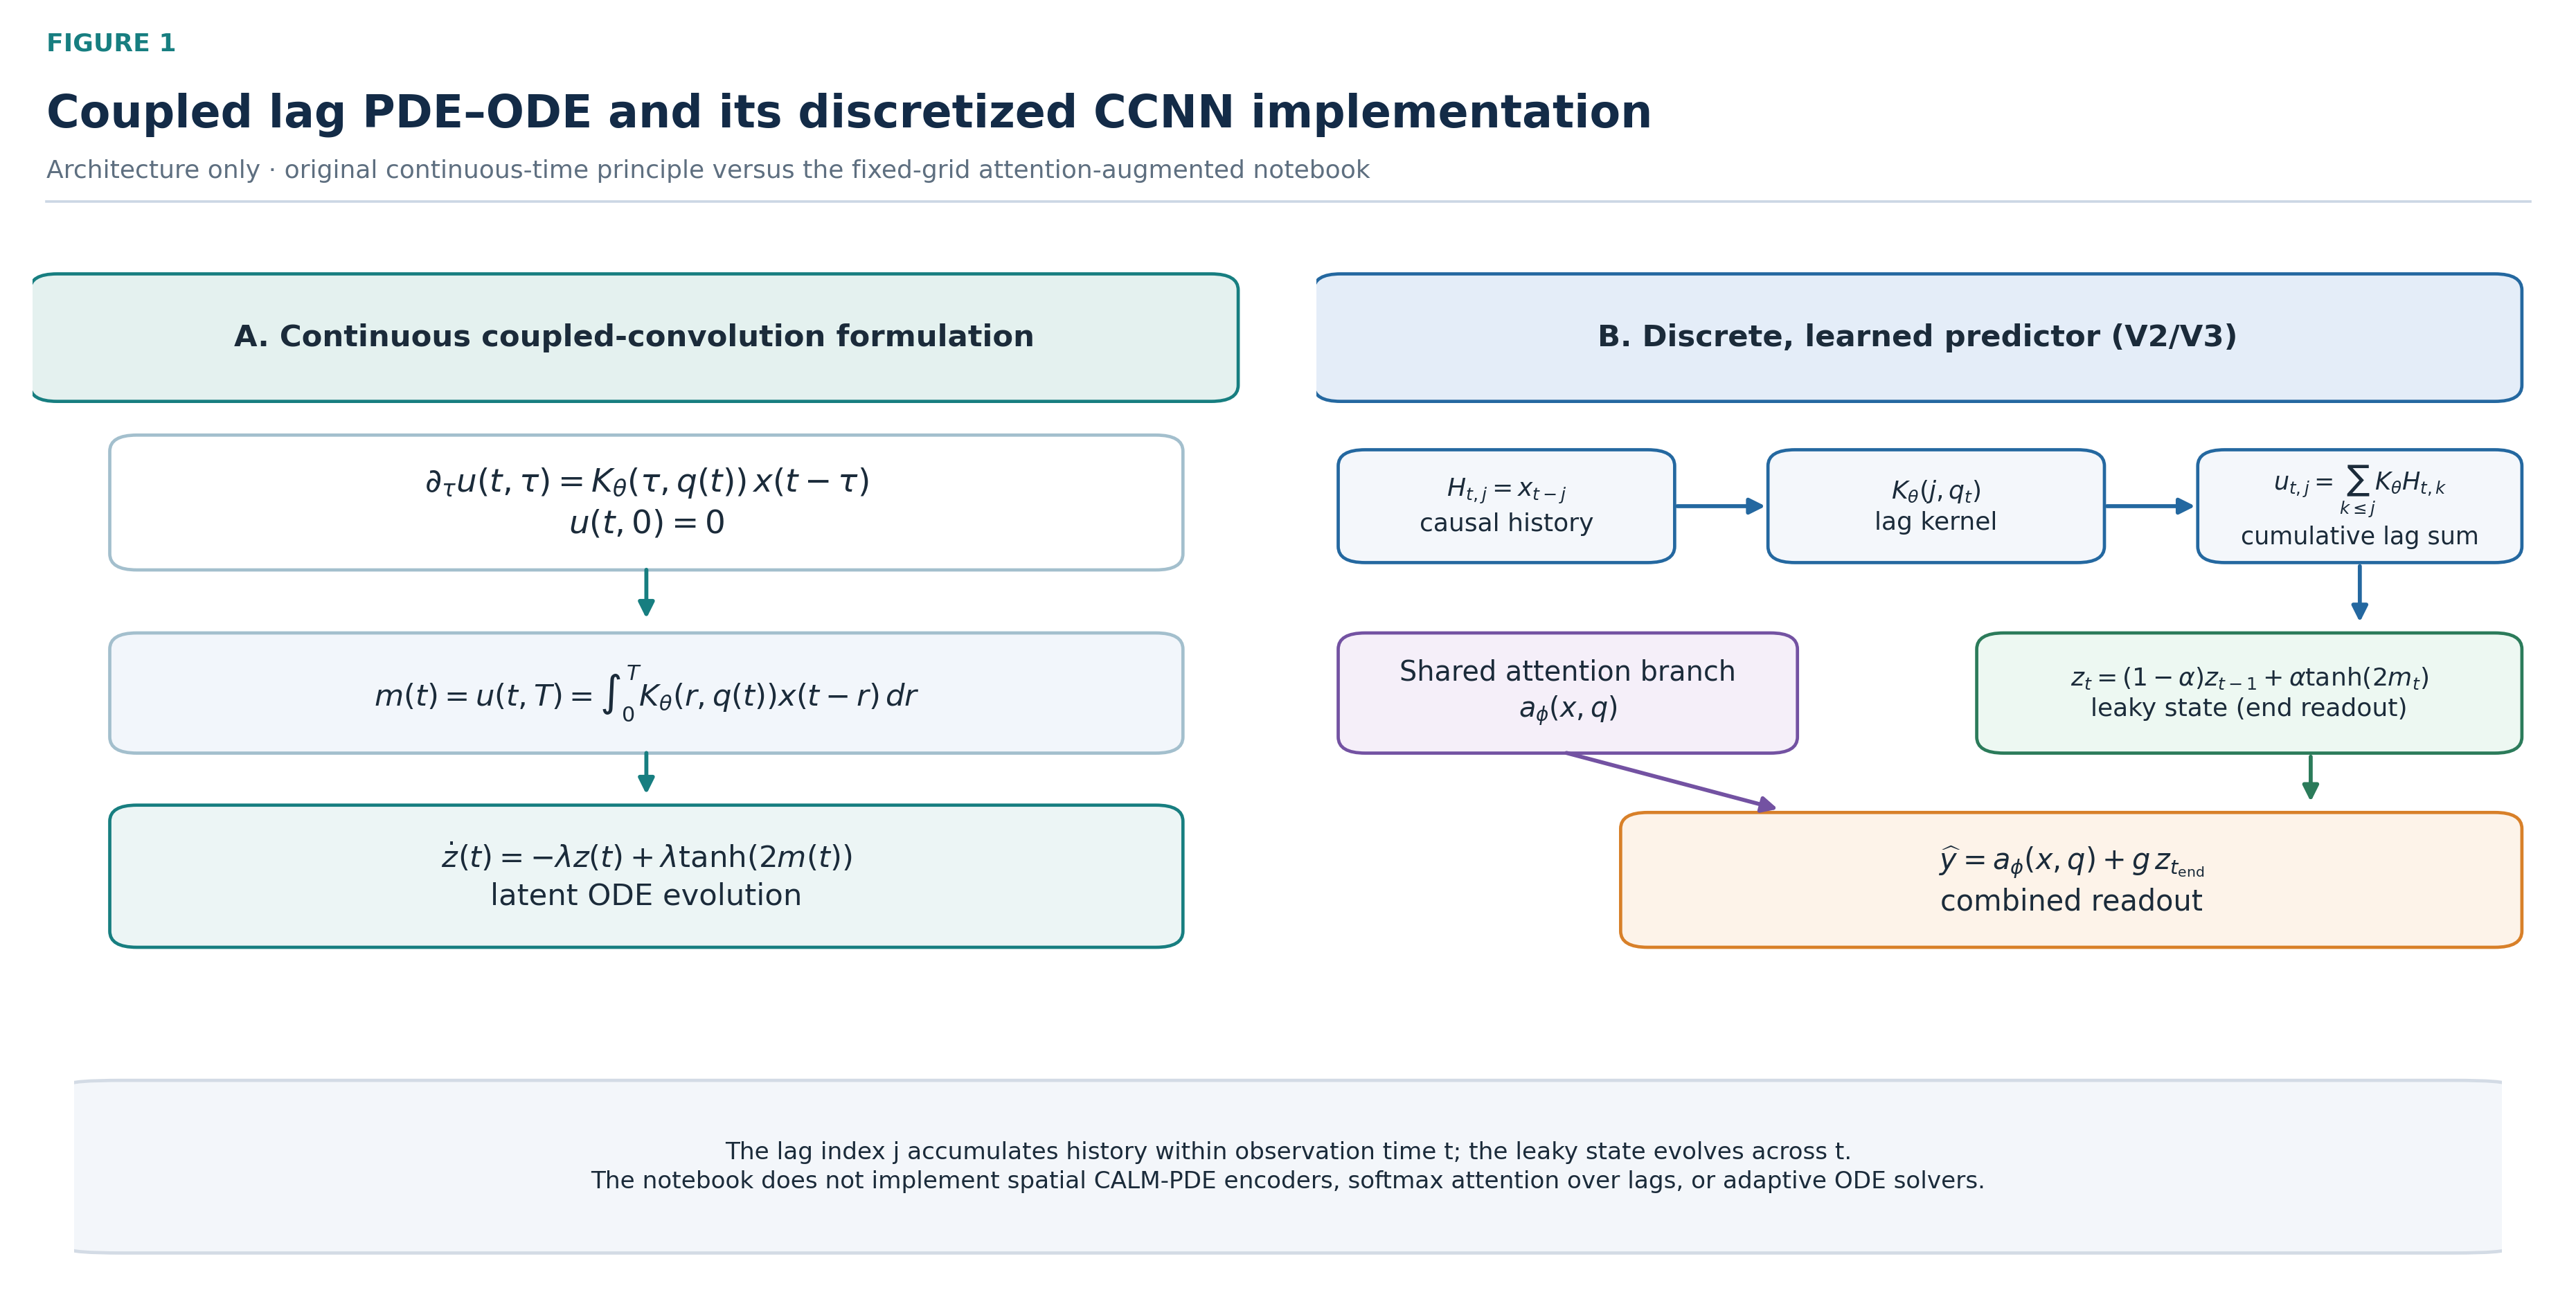


### Standalone Figure 2 — Repair Parameterizations

*Structure-aware versus unstructured repair on a shared frozen CCNN*

Repair parameterizations are compared on an identical frozen CCNN source model. Candidates include low-budget mechanism-specific updates, unstructured spectral coefficients, low-rank factors and a full query-conditioned FIR residual. Edit budgets are fixed at predeclared parameter counts and the resulting shared weights are evaluated on both shifted-domain and original-domain data without a gate. Structured arms above five parameters contain additional spectral residual coefficients and are hybrid models.

**Status: explanatory schematic — not numerical evidence.**

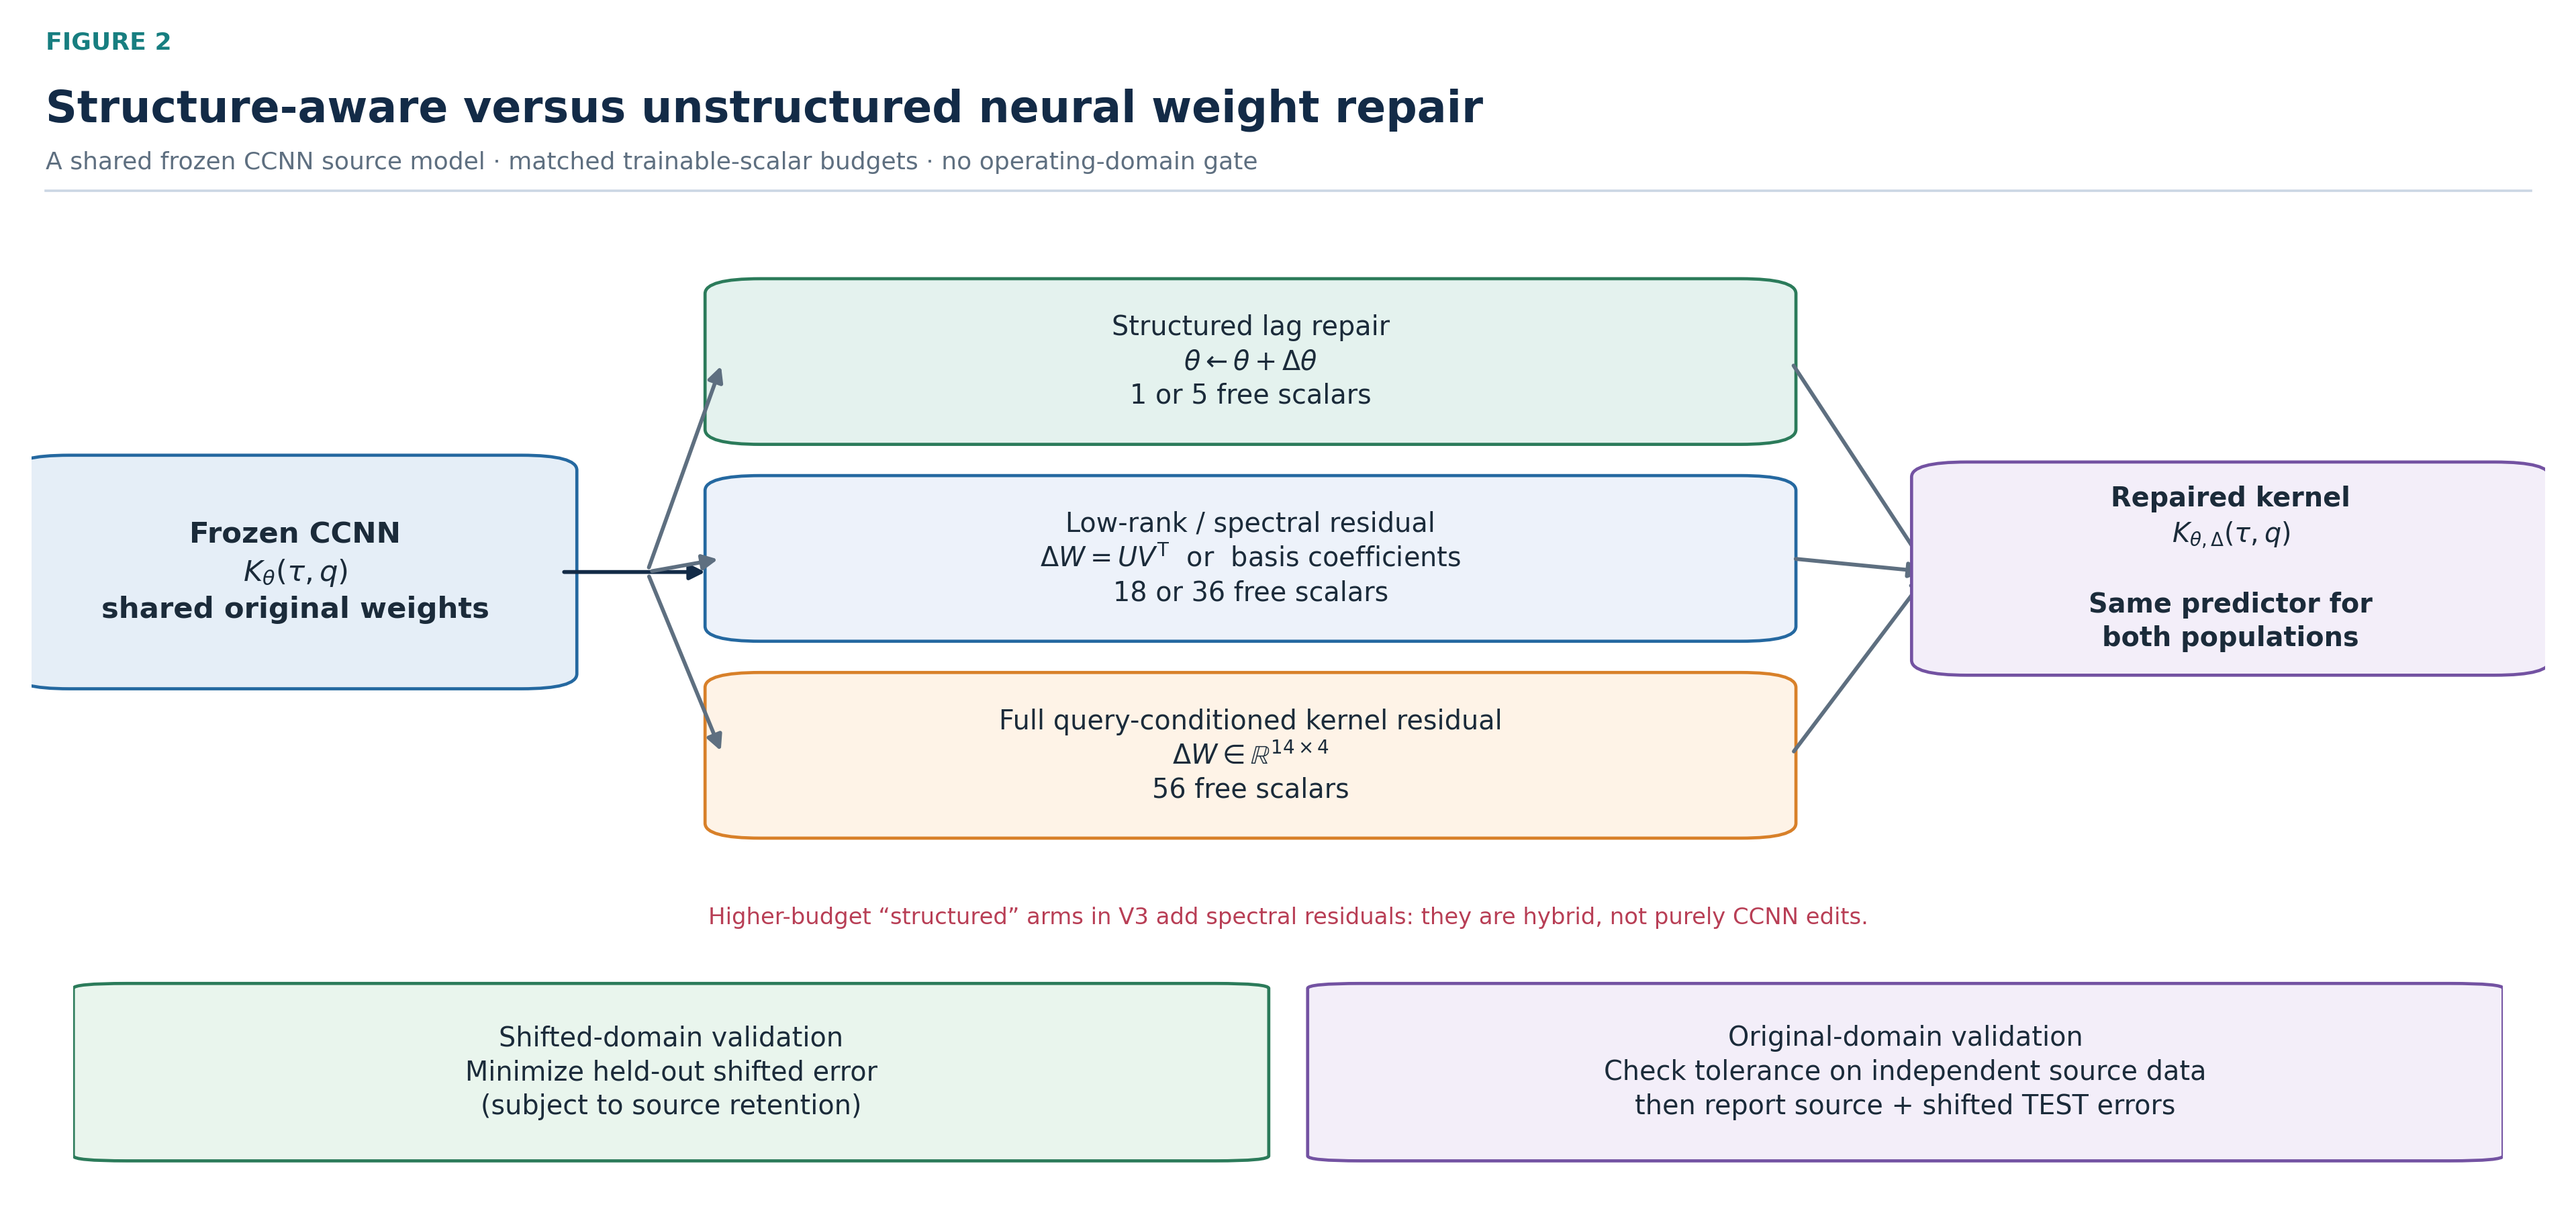


### Standalone Figure 3 — Falsification Controls

*Unmatched kernel families and decisive independent controls*

Analytical kernels generated for the matched chirp, mismatched bimodal, boxcar and damped-oscillator cases, along with switching and feedback-ODE controls. The final teacher changes downstream dynamics while retaining the same switching-type input kernel. Curves are reference teachers at two query conditions, not learned-kernel identifications. The evaluation includes matched edit budgets, independent original- and shifted-domain tests and no-fault controls.

**Status: analytical teacher curves — not learned-model weights.**

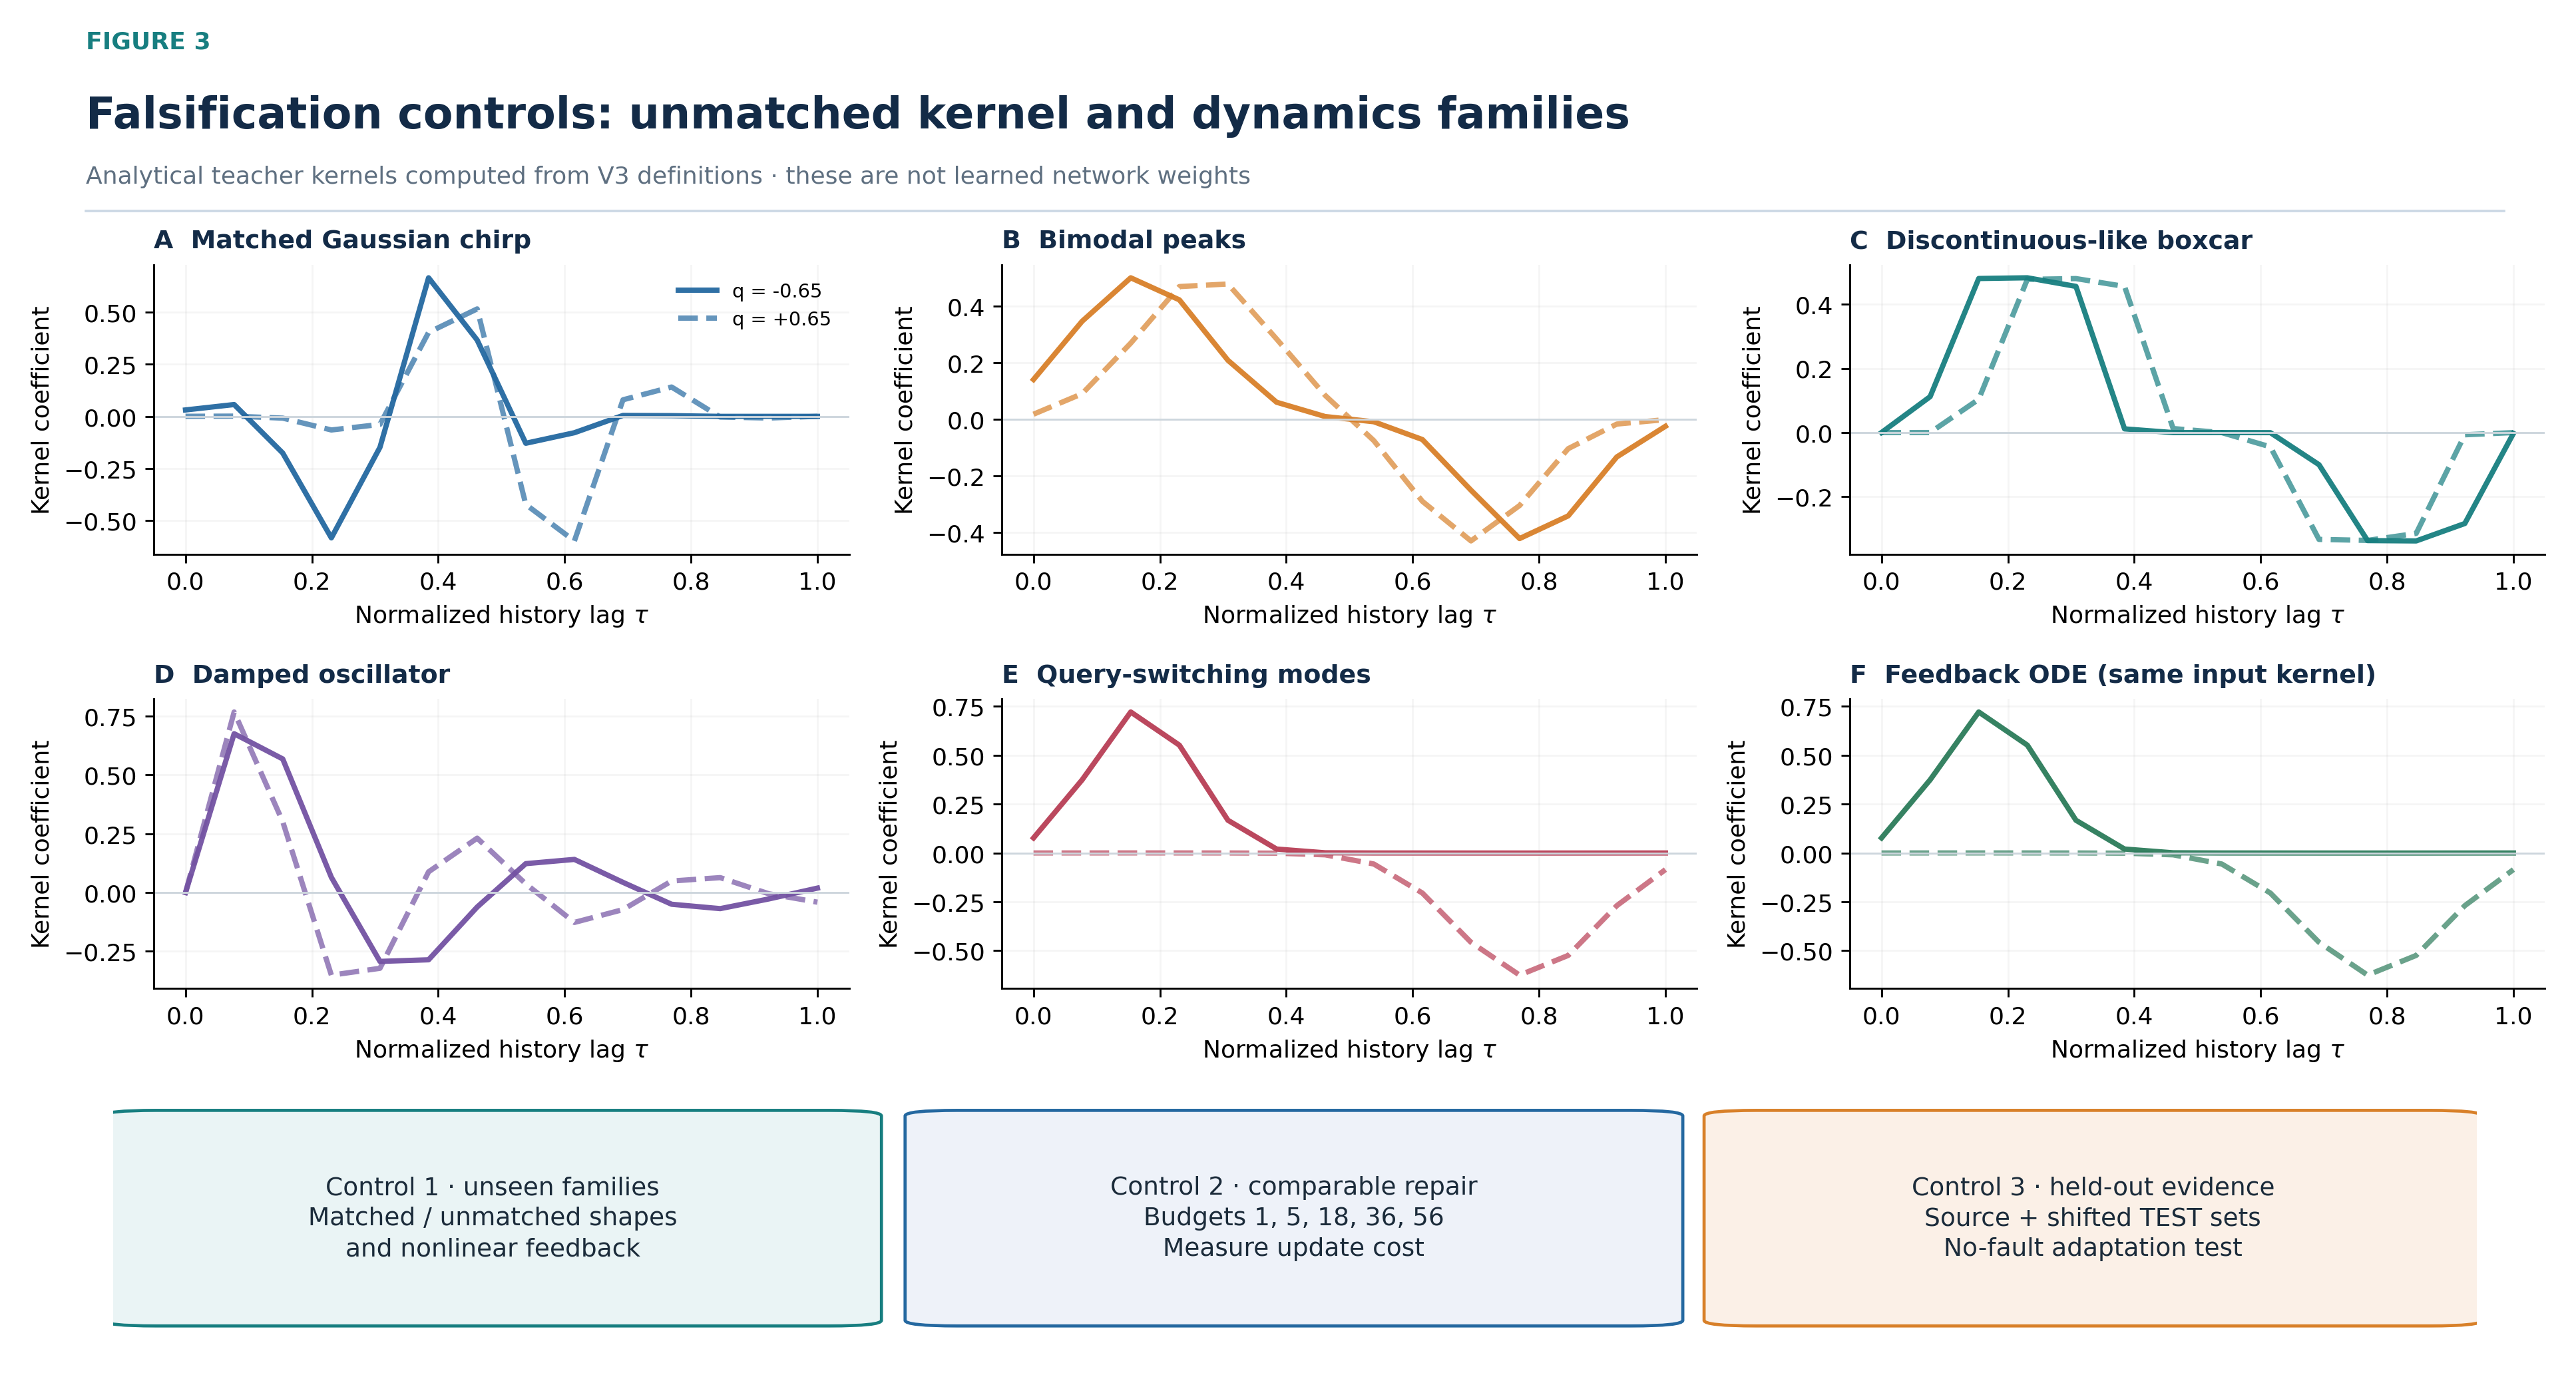


### Standalone Figure 4 — Measured Repair Loss Landscape

*Measured two-coordinate validation loss geometry and optimization paths*

Contour slices of log10 shifted-domain validation loss over the first two edit coefficients of five-parameter structured and spectral adapters, computed on a 12-epoch fitted CCNN from a single seed. A dashed curve indicates the original-domain validation tolerance, while trajectories represent gradient updates chosen using independent training populations. Only two coordinates are varied for contour plots, with the remaining coefficients set to zero; these plots do not establish global minima, high-dimensional curvature or superiority over larger update classes. This is exploratory, not independent replication.

**Status: exploratory empirical diagnostic — not independently replicated.**

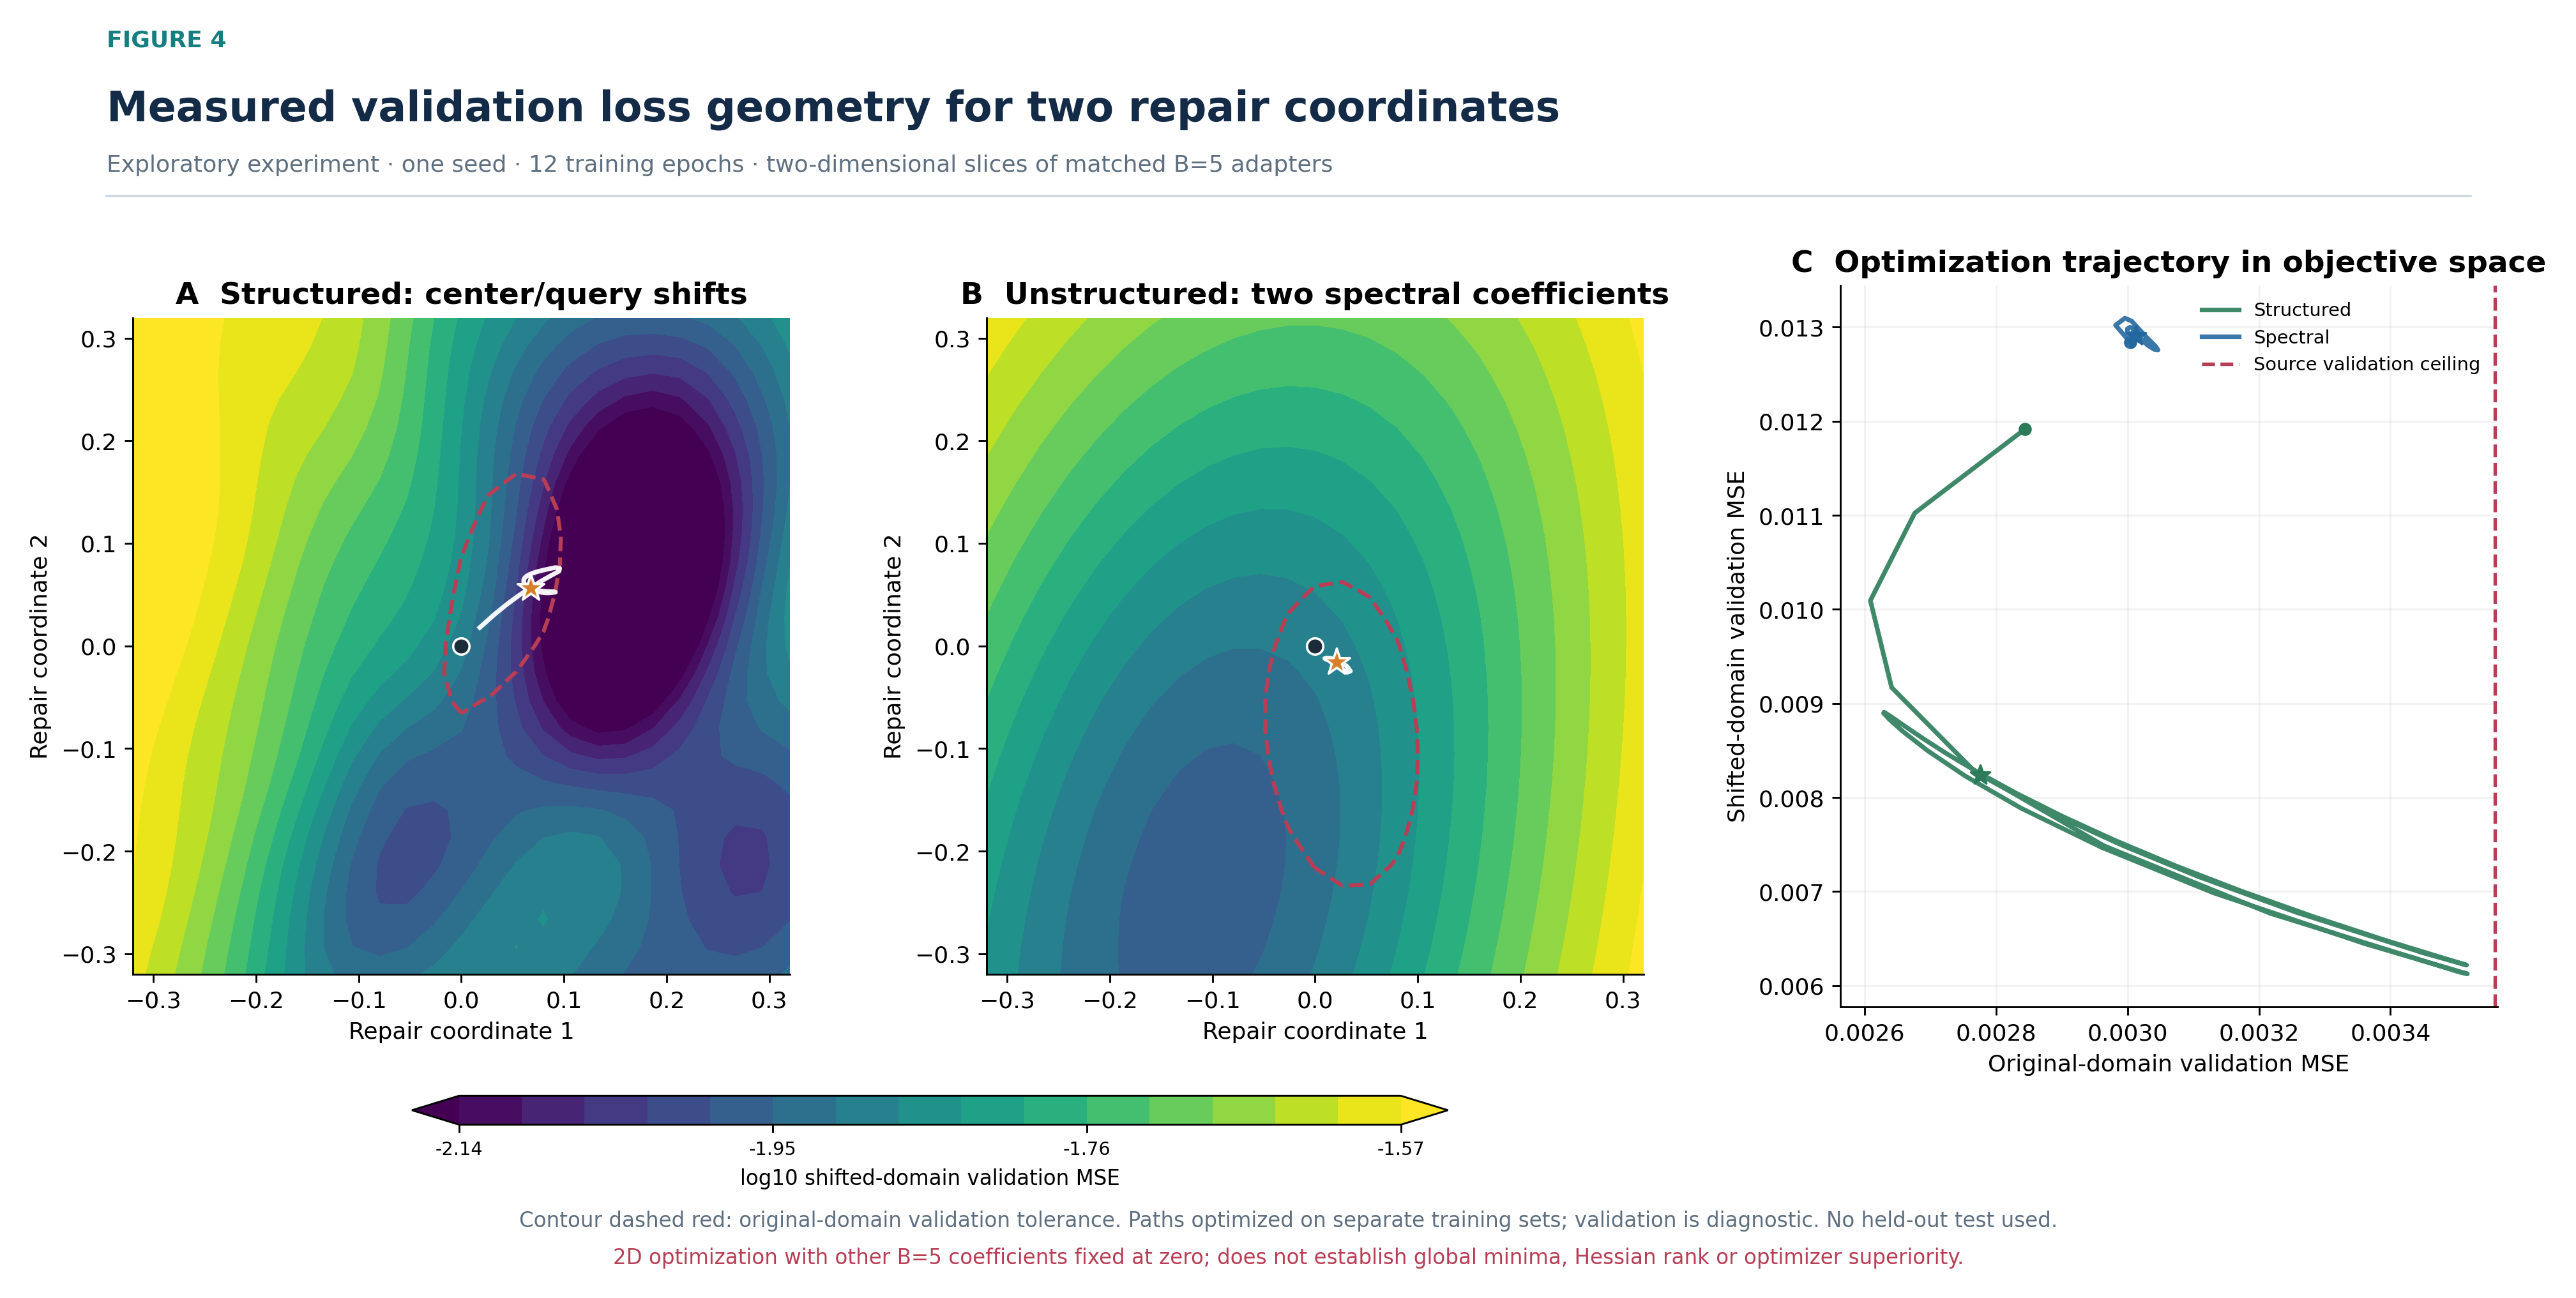


### Standalone Figure 5 — Exploratory Results

*One-seed architecture and ungated repair outcomes*

Architecture generalization and repair results from the previously executed local local unmatched-kernel smoke profile (three teacher families, one seed). CCNN underperforms the attention-only comparator on bimodal and boxcar families under this short training schedule. Shared ungated adapters achieve shifted-domain recovery without exceeding the independent source retention threshold in this run, but accepted edits in all twelve no-defect controls, indicating that initial source-model error and adaptation overfitting remain important confounders. These plots are not confirmatory and should not be used to claim broad architectural or optimization superiority.

**Status: exploratory empirical diagnostic — not independently replicated.**

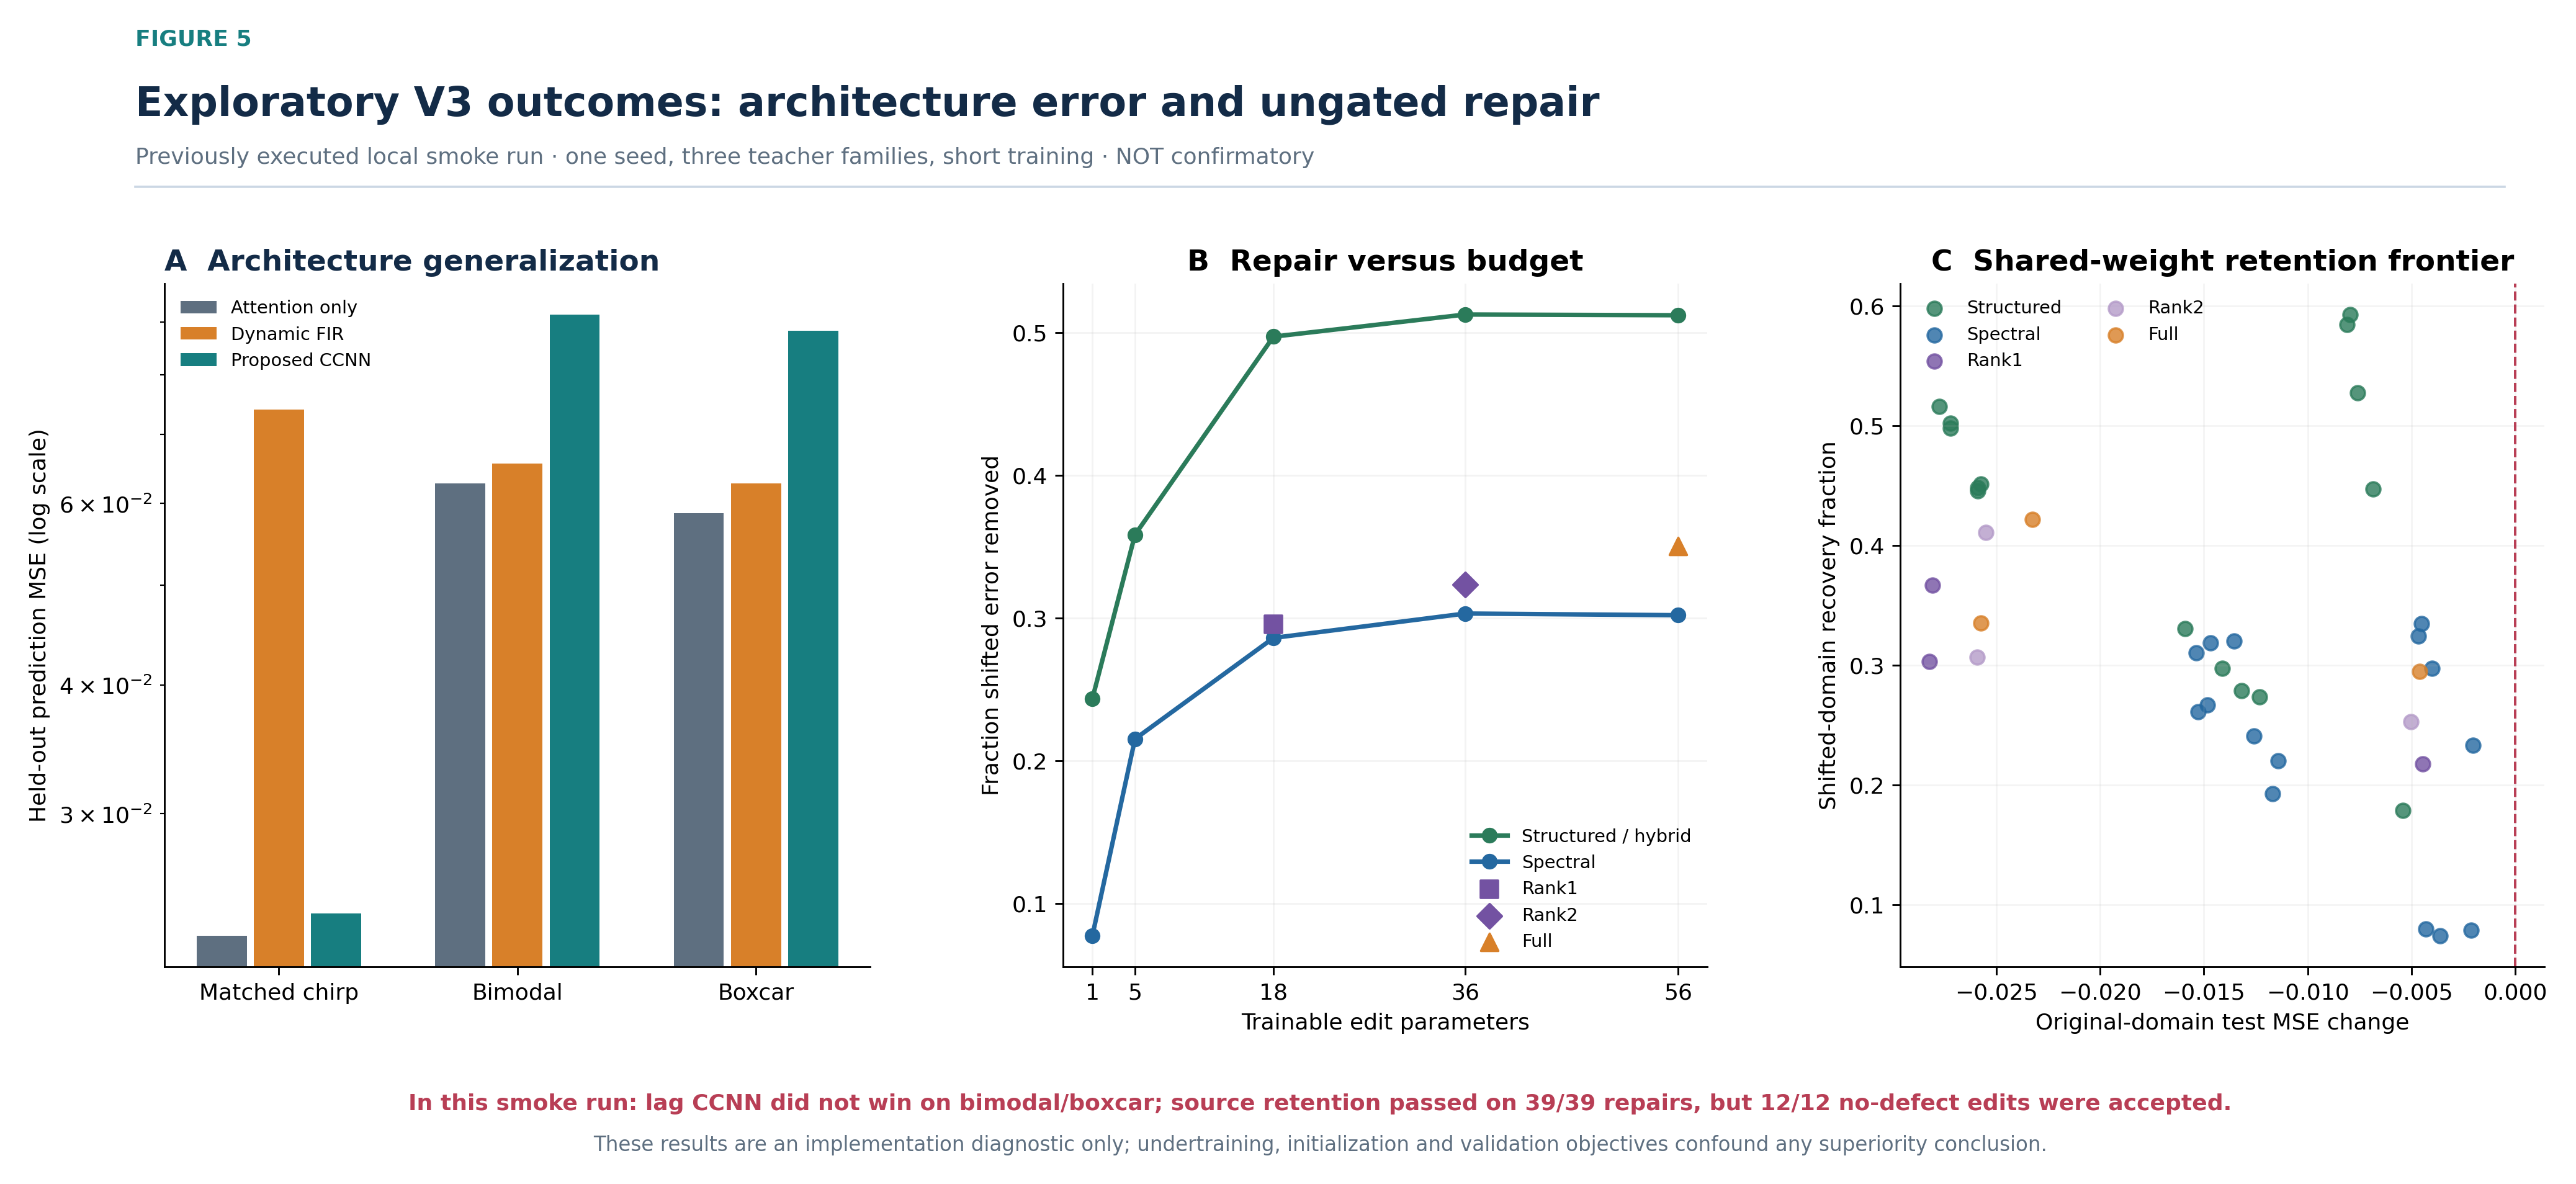


### Figure provenance and limitations

These five images reproduce the previously prepared **standalone** scientific figures, not new confirmatory results. They remain attached to this V2 notebook and render without local paths or cloud-drive mounting. To **recompute** the analytical teachers or independent measured surfaces, run the existing optional benchmark/landscape cells in Sections 10–13 with their explicit flags; the embedded one-seed snapshots should not be silently substituted for fresh results. Original V2 figures and figures 6–8 remain unmodified.

**Scientific decision:** retain the CCNN hypothesis conditionally; test unmatched kernel families, matched repair capacities and independently measured original-domain preservation without a domain gate.